<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-08/lab-045-schroedinger-pinn.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 045 <br>
<hr/>

# Lab 045 — Schrödinger equation with PINNs

A quantum particle in a harmonic trap prepared in a superposition of its two lowest eigenstates oscillates back and forth with a period fixed by the energy difference of the two states. We observe its wave function at three early times, all within the first sixth of one oscillation period, and ask how well the evolution over the whole period can be predicted from these snapshots. A neural network fitted to the snapshots alone has no information about later times. A physics-informed neural network (PINN) [M. Raissi, P. Perdikaris, G. E. Karniadakis, J. Comput. Phys. **378**, 686 (2019), [doi:10.1016/j.jcp.2018.10.045](https://doi.org/10.1016/j.jcp.2018.10.045)] is trained on the same snapshots and in addition on the residual of the Schrödinger equation on the whole space–time window. Raissi *et al.* used the nonlinear Schrödinger equation as one of their first examples, and we follow the same construction for the linear equation of the trapped particle.

In Example 1, Sections 1 to 6, we first describe the physics of the harmonic trap, its eigenstates and the exact evolution of the superposition. A split-step Fourier solver provides the classical reference and shows how cheaply the forward problem is solved by a standard method. The central experiment compares the two networks against the exact evolution through the density, its error, the norm and the mean position over time. Further sections test the energy and the phase of the predicted wave function, vary the number of snapshots and the noise, compare the cost with the classical solver and estimate an unknown trap frequency from the same snapshots.

Example 2, Sections 7 to 9, is quantum tunnelling in a symmetric double well. A particle prepared in the left well tunnels through the barrier to the right well and back within the tunnelling period $T_{\rm tun}=2\pi/\Delta E$, set by the small splitting $\Delta E$ of the two lowest levels. We compute the spectrum, describe the exact tunnelling oscillation, and ask the same question as before, now for three snapshots in the first 15 % of one tunnelling period. We report what the PINN needed to succeed and which variants failed, and we estimate the unknown barrier height from the snapshots. A closing section relates the results to the physics contained in the residual, and the notebook ends with exercises.

The implementation uses JAX. The reference solutions run in double precision and the networks in single precision, the optimisers come from `optax`, and the split-step solver is our own implementation in JAX built on `jnp.fft`.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`. The whole notebook runs in about 20 minutes on a multi-core CPU.
> 2. `jax`, `optax`, `scipy` and `matplotlib` are pre-installed in Colab.
> 3. Run the cells *in order*. Later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch
from scipy.optimize import minimize_scalar

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # reference solutions in float64, networks in float32
import optax

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
COL = {"exact": "k", "PINN": "#7B4FA0", "data": DSOrange, "plain": "#2A9D8F", "SSF": UJBlue}

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

nums = {}                 # every number a slide may need, written to the numbers file at the end
t_start = time.time()
print("jax", jax.__version__, "| optax", optax.__version__)

jax 0.11.0 | optax 0.2.6


<hr/>
## 1. Particle in a harmonic trap

A particle of mass $m_0$ in the potential $V(x)=\tfrac12m_0\omega^2x^2$ is described by its wave function $\psi(x,t)$, a complex number at every position $x$ and time $t$. Its squared modulus $|\psi(x,t)|^2$ is the probability density of finding the particle at $x$. The wave function evolves according to the time-dependent Schrödinger equation
$$i\hbar\,\partial_t\psi=-\frac{\hbar^2}{2m_0}\partial_x^2\psi+\tfrac12m_0\omega^2x^2\psi .$$
We measure lengths in units of the oscillator length $\sqrt{\hbar/(m_0\omega)}$, times in units of $1/\omega$ and energies in units of $\hbar\omega$. In these units $\hbar=m_0=\omega=1$ and the equation reads
$$i\,\partial_t\psi=\hat H\psi,\qquad \hat H=-\tfrac12\partial_x^2+\tfrac12x^2 .$$
A stationary state $\psi(x,t)=\phi_n(x)\,e^{-iE_nt}$ has a time-independent density, and its spatial part solves the eigenvalue equation $\hat H\phi_n=E_n\phi_n$. For the harmonic trap the normalised eigenfunctions are the Hermite functions with the energies $E_n=n+\tfrac12$ [D. J. Griffiths, D. F. Schroeter, *Introduction to Quantum Mechanics*, 3rd ed., Cambridge University Press (2018), [doi:10.1017/9781316995433](https://doi.org/10.1017/9781316995433)],
$$\phi_n(x)=\frac{1}{\sqrt{2^n\,n!\,\sqrt\pi}}\,H_n(x)\,e^{-x^2/2},\qquad n=0,1,2,\dots ,$$
where $H_n$ is the Hermite polynomial of degree $n$. The function $\phi_n$ has $n$ nodes and the parity $(-1)^n$, so $\phi_0$ is a Gaussian, $\phi_1$ is odd and $\phi_2$ is even again. We evaluate the Hermite functions with the recurrence
$$\phi_0(x)=\pi^{-1/4}e^{-x^2/2},\qquad \phi_1(x)=\sqrt2\,x\,\phi_0(x),\qquad \phi_{n+1}(x)=\sqrt{\frac{2}{n+1}}\,x\,\phi_n(x)-\sqrt{\frac{n}{n+1}}\,\phi_{n-1}(x),$$
which avoids the large coefficients of $H_n$.

All numerical work uses the box $-L\le x<L$ with $L=6$ and $N_x=256$ equally spaced points $x_j$ of spacing $\Delta x=2L/N_x$. The code checks the orthonormality $\langle\phi_m|\phi_n\rangle=\int\phi_m\phi_n\,dx=\delta_{mn}$ on this grid, evaluates the matrix element $\langle\phi_0|x|\phi_1\rangle$ that sets the mean position below, and diagonalises the Hamiltonian discretised with the three-point second difference $\partial_x^2\psi(x_j)\approx[\psi(x_{j+1})-2\psi(x_j)+\psi(x_{j-1})]/\Delta x^2$, whose lowest eigenvalues must approach $E_n=n+\tfrac12$.

In [2]:
L_BOX, N_X = 6.0, 256                         # spatial box [-L, L) and number of grid points
X = -L_BOX + 2 * L_BOX * np.arange(N_X) / N_X   # periodic grid used by all solvers and diagnostics
DX = X[1] - X[0]

def hermite_functions(n_max, x):
    # phi_0 ... phi_n_max by the stable three-term recurrence of the normalised Hermite functions
    phi = [np.pi**-0.25 * np.exp(-x**2 / 2)]
    phi.append(np.sqrt(2) * x * phi[0])
    for n in range(1, n_max):
        phi.append(np.sqrt(2 / (n + 1)) * x * phi[n] - np.sqrt(n / (n + 1)) * phi[n - 1])
    return np.array(phi[:n_max + 1])

PHI = hermite_functions(2, X)
E_N = np.arange(3) + 0.5                      # E_n = n + 1/2 in units of hbar omega
overlap = PHI @ PHI.T * DX
x01 = np.sum(X * PHI[0] * PHI[1]) * DX
# numerical check of the spectrum: lowest eigenvalues of the finite-difference Hamiltonian on the same grid
H_fd = (np.diag(1 / DX**2 + 0.5 * X**2) - np.diag(np.full(N_X - 1, 0.5 / DX**2), 1)
        - np.diag(np.full(N_X - 1, 0.5 / DX**2), -1))
E_fd = np.linalg.eigvalsh(H_fd)[:3]
print(f"max |<phi_m|phi_n> - delta_mn| = {np.abs(overlap - np.eye(3)).max():.1e}")
print(f"<phi_0|x|phi_1> = {x01:.6f}, 1/sqrt(2) = {1/np.sqrt(2):.6f}")
print("lowest eigenvalues of the finite-difference Hamiltonian:", np.round(E_fd, 4))
edge = np.abs(hermite_functions(2, np.array([-L_BOX, L_BOX]))).max()
print(f"largest |phi_n(+-L)| for n <= 2: {edge:.1e}")
nums["E_fd"] = E_fd.tolist(); nums["x01"] = x01; nums["ortho"] = float(np.abs(overlap - np.eye(3)).max()); nums["edge"] = float(edge)

max |<phi_m|phi_n> - delta_mn| = 5.9e-14
<phi_0|x|phi_1> = 0.707107, 1/sqrt(2) = 0.707107
lowest eigenvalues of the finite-difference Hamiltonian: [0.4999 1.4997 2.4991]
largest |phi_n(+-L)| for n <= 2: 5.7e-07


The three Hermite functions are orthonormal on the grid to $5.9\times10^{-14}$, and at the edges of the box they are below $5.7\times10^{-7}$, so the tails outside the box of half-width 6 are negligible at this numerical accuracy. The matrix element $\langle\phi_0|x|\phi_1\rangle$ equals $1/\sqrt2=0.707107$. The lowest eigenvalues of the finite-difference Hamiltonian are 0.4999, 1.4997 and 2.4991, close to $\tfrac12$, $\tfrac32$ and $\tfrac52$, with deviations that come from the error of order $\Delta x^2$ of the three-point formula. The finite-difference matrix assumes zero values outside the box, while the Fourier-grid Hamiltonian and the split-step solver are periodic on the same grid. The tails of the low-energy states are small enough that this difference of boundary conditions has no effect at the accuracy considered here. The figure shows the potential $V(x)=x^2/2$, the energies $E_n$ as horizontal lines and the eigenfunctions $\phi_n(x)$, scaled by 0.6 and shifted vertically by $E_n$.

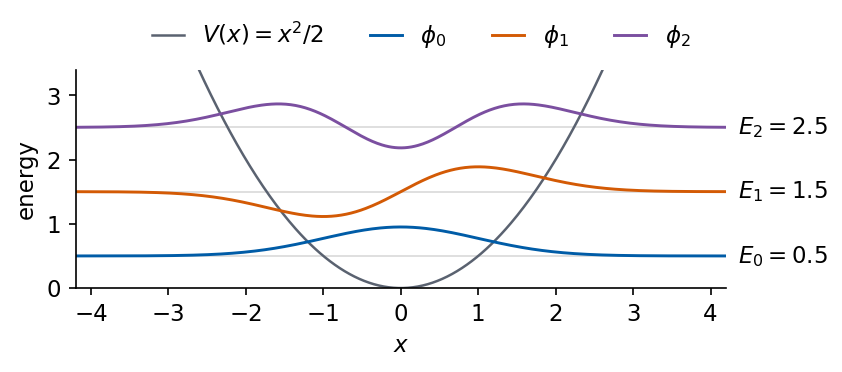

In [3]:
xx = np.linspace(-4.2, 4.2, 400)
phis = hermite_functions(2, xx)
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.4), layout="constrained")
    ax.plot(xx, 0.5 * xx**2, color=UJGray, lw=1.2, label=r"$V(x)=x^2/2$")
    cols = [UJBlue, DSOrange, COL["PINN"]]
    for n in range(3):
        ax.axhline(E_N[n], color="0.85", lw=0.8, zorder=0)
        ax.plot(xx, E_N[n] + 0.6 * phis[n], color=cols[n], label=rf"$\phi_{n}$")
        ax.text(4.35, E_N[n], rf"$E_{n}={E_N[n]:.1f}$", va="center", ha="left")
    ax.set_xlim(-4.2, 4.2); ax.set_ylim(0, 3.4); ax.set_xlabel("$x$"); ax.set_ylabel("energy")
    fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncol=4, handlelength=1.4)
    save(fig, "fig_lab045_eigenstates"); plt.show()

### Superposition of two eigenstates

The Schrödinger equation is linear, so a superposition of stationary states evolves by giving each component its own phase,
$$\psi(x,t)=\sum_nc_n\,\phi_n(x)\,e^{-iE_nt},\qquad c_n=\langle\phi_n|\psi(\cdot,0)\rangle=\int\phi_n(x)\,\psi(x,0)\,dx .$$
We prepare the particle in the state $\psi(x,0)=[\phi_0(x)+\phi_1(x)]/\sqrt2$. With real $\phi_n$ the density is
$$|\psi(x,t)|^2=\tfrac12\Big[\phi_0(x)^2+\phi_1(x)^2+2\,\phi_0(x)\phi_1(x)\cos\big((E_1-E_0)t\big)\Big] .$$
The interference term oscillates with the angular frequency $E_1-E_0=1$, so the density returns to its initial form after the period $2\pi$. Since $\phi_0\phi_1$ is positive for $x>0$ and negative for $x<0$, the density is shifted to the right at $t=0$ and to the left at $t=\pi$.

Two quantities characterise this motion. The norm
$$N(t)=\int|\psi(x,t)|^2\,dx=\tfrac12\Big[1+1+2\cos t\int\phi_0\phi_1\,dx\Big]=1$$
is constant because $\phi_0$ and $\phi_1$ are orthogonal, and for any state its conservation follows from the Hermiticity of $\hat H$. It is the total probability of finding the particle somewhere. The mean position
$$\langle x\rangle(t)=\frac{1}{N(t)}\int x\,|\psi(x,t)|^2\,dx$$
contains three integrals. The two integrals $\int x\,\phi_n^2\,dx$ vanish since $\phi_n^2$ is even, and
$$\int x\,\phi_0\phi_1\,dx=\frac{\sqrt2}{\sqrt\pi}\int x^2e^{-x^2}\,dx=\frac{\sqrt2}{\sqrt\pi}\cdot\frac{\sqrt\pi}{2}=\frac{1}{\sqrt2},$$
so that
$$\langle x\rangle(t)=\frac{\cos t}{\sqrt2} .$$
The wave packet oscillates like a classical particle in the trap with the trap frequency, as required by the Ehrenfest theorem $d\langle x\rangle/dt=\langle p\rangle$, $d\langle p\rangle/dt=-\langle x\rangle$ for the harmonic potential. We study the evolution on the window $0\le t\le t_{\max}$ with $t_{\max}=2\pi$, one full period, and evaluate all diagnostics at 129 equally spaced times in this window. The code evaluates $N(t)$ and $\langle x\rangle(t)$ on the grid from the exact wave function.

In [4]:
C_N = np.array([1.0, 1.0]) / np.sqrt(2)       # psi(x, 0) = (phi_0 + phi_1)/sqrt(2)
T_MAX = 2 * np.pi                              # one period of the density

def psi_exact(x, t):
    # sum_n c_n phi_n(x) exp(-i E_n t); x and t broadcast
    ph = hermite_functions(len(C_N) - 1, np.asarray(x, float))
    t = np.asarray(t, float)[..., None]
    return np.sum(C_N * np.moveaxis(ph, 0, -1) * np.exp(-1j * E_N[:len(C_N)] * t), axis=-1)

def diagnostics(psi):
    # psi[t, x] on the grid X: norm N(t) and mean position <x>(t) = int x |psi|^2 dx / N(t)
    dens = np.abs(psi)**2
    norm = dens.sum(-1) * DX
    return dens, norm, (dens * X).sum(-1) * DX / norm

T_GRID = np.linspace(0, T_MAX, 129)            # times of all diagnostics, spacing 2 pi / 128
PSI_EX = psi_exact(X[None, :], T_GRID[:, None])
DENS_EX, NORM_EX, XM_EX = diagnostics(PSI_EX)
nums["psi_max"] = float(np.abs(PSI_EX).max())   # largest modulus of the exact solution on the grid
print(f"max |N(t) - 1| = {np.abs(NORM_EX - 1).max():.1e}, "
      f"max |<x>(t) - cos(t)/sqrt(2)| = {np.abs(XM_EX - np.cos(T_GRID) / np.sqrt(2)).max():.1e}")
print(f"density at t = 2 pi equals the initial density to {np.abs(DENS_EX[-1] - DENS_EX[0]).max():.1e}")

max |N(t) - 1| = 1.2e-15, max |<x>(t) - cos(t)/sqrt(2)| = 2.2e-15
density at t = 2 pi equals the initial density to 0.0e+00


On the grid the norm deviates from 1 by $1.2\times10^{-15}$ and the mean position from $\cos t/\sqrt2$ by $2.2\times10^{-15}$, and the density at $t=2\pi$ coincides with the initial one. The left panel shows the exact density $|\psi(x,t)|^2$ as a map in the plane of time $t$ (horizontal) and position $x$ (vertical). The bright region moves from $x>0$ to $x<0$ and back within one period. The right panel shows the mean position $\langle x\rangle(t)$ computed on the grid together with $\cos t/\sqrt2$.

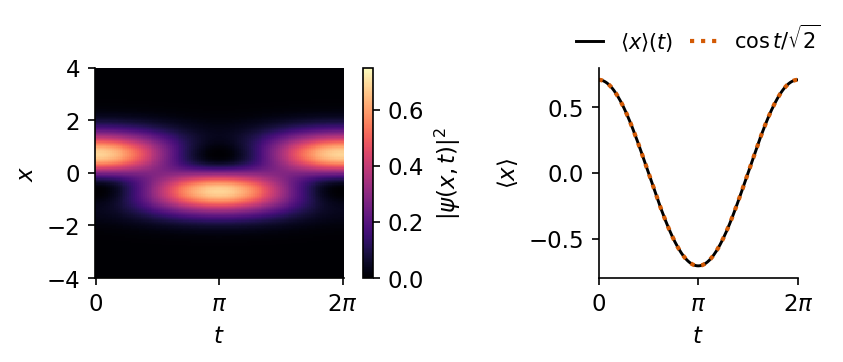

In [5]:
def density_map(ax, dens, vmax=0.75, snaps=None):
    # space-time map of a density, time on the horizontal axis
    im = ax.pcolormesh(T_GRID, X, dens.T, cmap="magma", vmin=0, vmax=vmax, shading="auto", rasterized=True)
    if snaps is not None:
        for tk in snaps:
            ax.axvline(tk, color="w", ls=":", lw=1.0)
    ax.set_ylim(-4, 4); ax.set_xlabel("$t$"); ax.set_ylabel("$x$")
    ax.set_xticks([0, np.pi, 2 * np.pi]); ax.set_xticklabels(["0", r"$\pi$", r"$2\pi$"])
    return im

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained", gridspec_kw={"width_ratios": [1.25, 1]})
    fig.get_layout_engine().set(wspace=0.08)
    im = density_map(axs[0], DENS_EX)
    fig.colorbar(im, ax=axs[0], label=r"$|\psi(x,t)|^2$", pad=0.02)
    axs[1].plot(T_GRID, XM_EX, color=COL["exact"], label=r"$\langle x\rangle(t)$")
    axs[1].plot(T_GRID, np.cos(T_GRID) / np.sqrt(2), ":", color=DSOrange, lw=2.0, label=r"$\cos t/\sqrt{2}$")
    axs[1].set_xlabel("$t$"); axs[1].set_ylabel(r"$\langle x\rangle$"); axs[1].set_xlim(0, T_MAX)
    axs[1].set_xticks([0, np.pi, 2 * np.pi]); axs[1].set_xticklabels(["0", r"$\pi$", r"$2\pi$"])
    axs[1].set_ylim(-0.8, 0.8)
    axs[1].legend(loc="lower center", bbox_to_anchor=(0.5, 0.98), ncol=2, handlelength=1.3, fontsize=10, columnspacing=0.8)
    save(fig, "fig_lab045_exact_density"); plt.show()

<hr/>
## 2. Split-step Fourier method

The Hamiltonian is the sum of the kinetic energy $\hat T=-\tfrac12\partial_x^2$ and the potential $\hat V=\tfrac12x^2$. The potential acts as a multiplication in position space. The kinetic energy acts as a multiplication by $p^2/2$ in momentum space, where the momentum $p$ equals, for $\hbar=1$, the wave number of a plane wave $e^{ipx}$. The split-step Fourier method [J. A. Fleck, J. R. Morris, M. D. Feit, Appl. Phys. **10**, 129 (1976), [doi:10.1007/BF00896333](https://doi.org/10.1007/BF00896333)] uses both representations. Over a time step $\Delta t$ it replaces the exact propagator $e^{-i\hat H\Delta t}$ by the symmetric product of the Strang splitting [G. Strang, SIAM J. Numer. Anal. **5**, 506 (1968), [doi:10.1137/0705041](https://doi.org/10.1137/0705041)],
$$\psi(t+\Delta t)\approx e^{-iV\Delta t/2}\;\mathcal F^{-1}\,e^{-ip^2\Delta t/2}\,\mathcal F\;e^{-iV\Delta t/2}\,\psi(t),$$
where $\mathcal F$ is the discrete Fourier transform on the periodic grid and $p_m=2\pi m/(2L)$ are its momenta. Every factor is unitary, so the norm is conserved to round-off for any $\Delta t$. The product differs from the exact propagator through the commutator $[\hat T,\hat V]$, by an amount of order $\Delta t^3$ per step, and the error after a fixed time decreases as $\Delta t^2$.

Our split-step Fourier implementation in JAX applies this step with `jnp.fft` inside `jax.lax.scan`. The same transforms are available as `numpy.fft` and `scipy.fft` in NumPy code. We propagate $\psi(x,0)$ to $t=2\pi$ with 32 to 2048 steps and record the largest deviation from the exact wave function at $t=2\pi$, the largest deviation of the norm from 1 and the wall time, the median over repeated calls of the compiled function.

In [6]:
K = 2 * np.pi * np.fft.fftfreq(N_X, d=DX)       # wave numbers of the periodic grid
X_J, K_J = jnp.asarray(X), jnp.asarray(K)

def split_step(psi0, dt, n_steps, omega=1.0, V=None):
    # Strang splitting: half potential step, full kinetic step in Fourier space, half potential step;
    # V on the grid replaces the harmonic potential when given
    half_v = jnp.exp(-0.5j * dt * (0.5 * omega**2 * X_J**2 if V is None else V))
    kin = jnp.exp(-0.5j * dt * K_J**2)
    def step(psi, _):
        psi = half_v * jnp.fft.ifft(kin * jnp.fft.fft(half_v * psi))
        return psi, psi
    _, psis = jax.lax.scan(step, jnp.asarray(psi0, jnp.complex128), None, length=n_steps)
    return jnp.concatenate([jnp.asarray(psi0, jnp.complex128)[None], psis])

def timed(fn, repeat=20):
    # median wall time of a compiled function, after one call for compilation
    jax.block_until_ready(fn()); ts = []
    for _ in range(repeat):
        t0 = time.perf_counter(); jax.block_until_ready(fn()); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

ssf_rows = []
for n_steps in (32, 64, 128, 256, 512, 1024, 2048):
    dt = T_MAX / n_steps
    fn = jax.jit(lambda: split_step(PSI_EX[0], dt, n_steps))
    psis = np.asarray(fn())
    err = np.abs(psis[-1] - PSI_EX[-1]).max()
    drift = np.abs((np.abs(psis)**2).sum(-1) * DX - 1).max()
    ssf_rows.append(dict(dt=dt, n=n_steps, err=float(err), drift=float(drift), time=timed(fn)))
    print(f"dt = {dt:.4f} ({n_steps:5d} steps): max |psi_SSF - psi| at t = 2 pi {err:.1e}, "
          f"max |N - 1| {drift:.1e}, wall time {ssf_rows[-1]['time']:.1e} s")
nums["ssf"] = ssf_rows

dt = 0.1963 (   32 steps): max |psi_SSF - psi| at t = 2 pi 8.7e-03, max |N - 1| 1.3e-15, wall time 3.4e-04 s
dt = 0.0982 (   64 steps): max |psi_SSF - psi| at t = 2 pi 2.2e-03, max |N - 1| 5.3e-15, wall time 4.7e-04 s


dt = 0.0491 (  128 steps): max |psi_SSF - psi| at t = 2 pi 5.4e-04, max |N - 1| 4.4e-15, wall time 1.1e-03 s


dt = 0.0245 (  256 steps): max |psi_SSF - psi| at t = 2 pi 1.3e-04, max |N - 1| 1.2e-14, wall time 2.2e-03 s
dt = 0.0123 (  512 steps): max |psi_SSF - psi| at t = 2 pi 3.4e-05, max |N - 1| 1.2e-14, wall time 5.0e-03 s


dt = 0.0061 ( 1024 steps): max |psi_SSF - psi| at t = 2 pi 8.4e-06, max |N - 1| 5.4e-14, wall time 9.1e-03 s


dt = 0.0031 ( 2048 steps): max |psi_SSF - psi| at t = 2 pi 2.1e-06, max |N - 1| 1.4e-13, wall time 1.5e-02 s


The error falls by a factor of four whenever $\Delta t$ is halved, from $8.7\times10^{-3}$ at $\Delta t=0.196$ to $2.1\times10^{-6}$ at $\Delta t=0.0031$, and the norm stays 1 to within $1.4\times10^{-13}$ for every step size. With 1024 steps, $\Delta t=0.0061$, the solver reaches $8.4\times10^{-6}$ in $7.5\times10^{-3}$ s. This run is our reference for the cost comparison below. The figure shows the error at $t=2\pi$ against $\Delta t$ together with a line proportional to $\Delta t^2$.

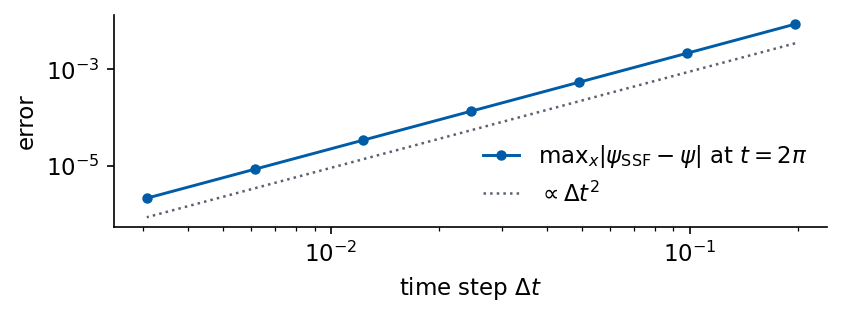

In [7]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.0), layout="constrained")
    dts = np.array([r["dt"] for r in ssf_rows]); errs = np.array([r["err"] for r in ssf_rows])
    ax.loglog(dts, errs, "o-", color=COL["SSF"], ms=4, label=r"max$_x|\psi_{\rm SSF}-\psi|$ at $t=2\pi$")
    ax.loglog(dts, 0.4 * errs[0] * (dts / dts[0])**2, ":", color=UJGray, lw=1.2, label=r"$\propto\Delta t^2$")
    ax.set_xlabel(r"time step $\Delta t$"); ax.set_ylabel("error"); ax.legend(loc="lower right", handlelength=1.6)
    save(fig, "fig_lab045_split_step"); plt.show()

<hr/>
## 3. Evolution from snapshots

We now assume that the wave function has been observed at three times $t_k=0,\ 0.5,\ 1.0$, all inside the first sixth of the period. Each snapshot contains the real and imaginary parts of $\psi$ at the 128 positions $x_j$ formed by every second grid point, and every value carries independent Gaussian noise of standard deviation $\sigma=0.01$,
$$\psi_{jk}=\psi(x_j,t_k)+\sigma\,(\varepsilon_{jk}+i\,\varepsilon'_{jk}),\qquad \varepsilon_{jk},\ \varepsilon'_{jk}\sim\mathcal N(0,1) .$$
A snapshot of the complex wave function corresponds to a full reconstruction of the quantum state at one time, which in an experiment requires quantum state tomography. Tomography returns the state only up to a global phase factor at each time, and a measurement of the position density gives only $|\psi|^2$. Our synthetic snapshots share one phase convention across the three times, so they carry more phase information than an experiment provides. We take these data as given and ask for $\psi(x,t)$ on the whole window $0\le t\le2\pi$, more than six times longer than the observation window $0\le t\le1$.

When the Hamiltonian is known, the task has two classical solutions. The first propagates the snapshot at $t=0$, linearly interpolated to the full grid, with the split-step solver. The second expands the snapshots in the eigenstates $\phi_0,\dots,\phi_9$ of the trap. Each snapshot gives the coefficients $\langle\phi_n|\psi(\cdot,t_k)\rangle$, approximated by the sum over the 128 data points with spacing $2\Delta x$. Undoing the phase $e^{-iE_nt_k}$ and averaging over the three snapshots gives
$$c_n=\frac13\sum_{k}e^{iE_nt_k}\,\langle\phi_n|\psi(\cdot,t_k)\rangle,$$
and the wave function at any time follows from $\psi(x,t)=\sum_nc_n\phi_n(x)e^{-iE_nt}$.

In [8]:
T_SNAP = np.array([0.0, 0.5, 1.0])            # times of the three snapshots
SIGMA = 0.01                                    # noise on Re psi and Im psi of every snapshot value
I_DATA = np.arange(0, N_X, 2)                   # every second grid point, 128 positions per snapshot
rng = np.random.default_rng(0)
psi_snap = psi_exact(X[I_DATA][None, :], T_SNAP[:, None])
psi_snap = psi_snap + SIGMA * (rng.normal(size=psi_snap.shape) + 1j * rng.normal(size=psi_snap.shape))
XD, TD = np.meshgrid(X[I_DATA], T_SNAP)
print(f"{psi_snap.size} complex values in {len(T_SNAP)} snapshots at t = {T_SNAP}, noise sigma = {SIGMA}")

# classical reference for the same task: propagate the noisy snapshot at t = 0 with the split-step solver
psi0_noisy = np.interp(X, X[I_DATA], psi_snap[0].real) + 1j * np.interp(X, X[I_DATA], psi_snap[0].imag)
n_ref = 1024; dt_ref = T_MAX / n_ref
psi_ssf_noisy = np.asarray(split_step(psi0_noisy, dt_ref, n_ref))[::n_ref // 128]
err_ssf_noisy = np.abs(psi_ssf_noisy - PSI_EX).max(-1)
_, norm_ssf_noisy, xm_ssf_noisy = diagnostics(psi_ssf_noisy)
print(f"split-step from the noisy snapshot at t = 0: max_x |psi - psi_exact| between {err_ssf_noisy.min():.1e} "
      f"and {err_ssf_noisy.max():.1e}, norm {norm_ssf_noisy[0]:.4f}")
# second classical reference: expand the three snapshots in the eigenstates phi_0 ... phi_9 of the known trap,
# c_n = (1/3) sum_k exp(i E_n t_k) <phi_n|psi(t_k)>, and evolve every coefficient with its phase
N_PROJ = 10
PHI_D = hermite_functions(N_PROJ - 1, X[I_DATA])
E_P = np.arange(N_PROJ) + 0.5
c_proj = np.mean(np.exp(1j * E_P[None, :] * T_SNAP[:, None]) * (psi_snap @ PHI_D.T) * 2 * DX, axis=0)
psi_proj = (c_proj * np.exp(-1j * E_P * T_GRID[:, None])) @ hermite_functions(N_PROJ - 1, X)
err_proj = np.abs(psi_proj - PSI_EX).max(-1)
print(f"eigenstate expansion of the three snapshots: |c_0|^2 = {abs(c_proj[0])**2:.4f}, |c_1|^2 = {abs(c_proj[1])**2:.4f},"
      f" sum over n >= 2 of |c_n|^2 = {np.sum(np.abs(c_proj[2:])**2):.1e}, max_x |psi - psi_exact| = {err_proj.max():.1e}")
nums["snap"] = dict(proj_err=float(err_proj.max()), c0=float(abs(c_proj[0])**2), c1=float(abs(c_proj[1])**2),
                    c_rest=float(np.sum(np.abs(c_proj[2:])**2)), ssf_noisy_min=float(err_ssf_noisy.min()), t=T_SNAP.tolist(), sigma=SIGMA, n_values=int(psi_snap.size), ssf_noisy_err=float(err_ssf_noisy.max()),
                    ssf_noisy_norm=float(norm_ssf_noisy[0]))

384 complex values in 3 snapshots at t = [0.  0.5 1. ], noise sigma = 0.01


split-step from the noisy snapshot at t = 0: max_x |psi - psi_exact| between 2.5e-02 and 4.0e-02, norm 1.0031
eigenstate expansion of the three snapshots: |c_0|^2 = 0.4997, |c_1|^2 = 0.5015, sum over n >= 2 of |c_n|^2 = 4.7e-05, max_x |psi - psi_exact| = 6.1e-03


Propagating the noisy first snapshot gives a maximal error between $2.5\times10^{-2}$ and $4.0\times10^{-2}$ at all times. The noise is part of the initial state and evolves unitarily together with it, so it is never removed. The expansion in eigenstates gives $|c_0|^2=0.4997$, $|c_1|^2=0.5015$ and $\sum_{n\ge2}|c_n|^2=4.7\times10^{-5}$, and a maximal error of $6.1\times10^{-3}$ over the whole window. The projection on ten smooth functions averages the noise of the 384 data values. Both references use the full knowledge of $\hat H$, the second one even its eigenstates.

### Network and loss

The network represents the wave function as $\psi_\theta(x,t)=u_\theta(x,t)+i\,v_\theta(x,t)$. A multilayer perceptron $N_\theta$ receives the rescaled inputs $x/L$ and $2t/t_{\max}-1$, both in $[-1,1]$, passes them through four hidden layers of 50 tanh units and returns two numbers through a linear output layer. They are multiplied by a fixed envelope,
$$\big(u_\theta(x,t),\,v_\theta(x,t)\big)=e^{-x^2/4}\,N_\theta(x,t).$$
The envelope makes $\psi_\theta$ decay towards the edges of the box, as every bound state of the trap does. Its width is $\sqrt2$ times that of the ground state $\phi_0\propto e^{-x^2/2}$, so the network still has to produce the Gaussian shape of $\phi_0$ and $\phi_1$ itself. The envelope is prior information about the spatial decay of bound states, and model A and the PINN share it. It suppresses the tails without forcing $\psi_\theta$ to vanish at the edges of the box, which a boundary term of the loss penalises. The same network without the envelope is trained further below.

Inserting $\psi_\theta=u_\theta+iv_\theta$ into $i\partial_t\psi=-\tfrac12\partial_x^2\psi+V\psi$ with $V(x)=\tfrac12x^2$ and separating the real and imaginary parts gives the two residuals
$$\begin{aligned}
f_u&=-\partial_tv_\theta+\tfrac12\partial_x^2u_\theta-V\,u_\theta,\\
f_v&=\partial_tu_\theta+\tfrac12\partial_x^2v_\theta-V\,v_\theta .
\end{aligned}$$
Both vanish at every point if and only if $\psi_\theta$ solves the Schrödinger equation. The derivatives come from forward-mode automatic differentiation. One Jacobian–vector product `jax.jvp` in $t$ gives $\partial_t(u_\theta,v_\theta)$ at all points of a batch at once, and two nested products in $x$ give $\partial_x^2(u_\theta,v_\theta)$. The drawing shows the network as nodes and edges, the envelope and the three terms of the loss defined below.

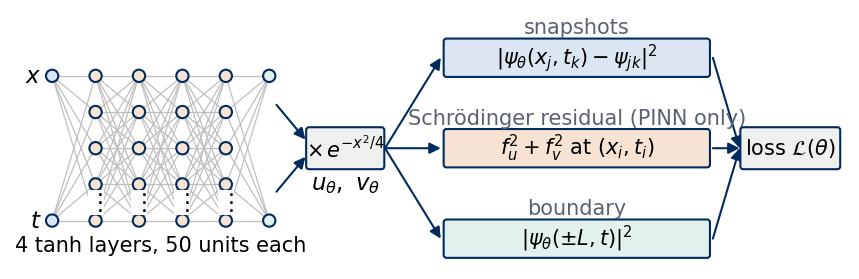

In [9]:
def draw_layers(ax, sizes, xs, ys_span=2.2, node_r=0.11, colors=None, edge_color="0.75"):
    """Nodes-and-edges drawing of a fully connected network, columns at x = xs."""
    cols = []
    for n, x in zip(sizes, xs):
        ys = np.linspace(ys_span / 2, -ys_span / 2, n) if n > 1 else np.array([0.0])
        cols.append([(x, y) for y in ys])
    for a, b in zip(cols[:-1], cols[1:]):            # edges first, so that the nodes are drawn on top
        for (x0, y0) in a:
            for (x1, y1) in b:
                ax.plot([x0, x1], [y0, y1], color=edge_color, lw=0.6, zorder=1)
    for i, col in enumerate(cols):
        for (x, y) in col:
            ax.add_patch(Circle((x, y), node_r, fc=(colors[i] if colors else "#DCE6F2"), ec=UJNavy, lw=1.0, zorder=3))
    return cols

def box(ax, x, y, text, w, h, fc, **kw):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.04", fc=fc, ec=UJNavy, lw=1.0, zorder=3))
    ax.text(x, y, text, ha="center", va="center", zorder=4, **kw)

def arrow(ax, p, q, **kw):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=UJNavy, lw=1.0, shrinkA=0, shrinkB=0, **kw), zorder=2)

WIDTH, DEPTH = 50, 4
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.4)); ax = fig.add_axes([0, 0, 1, 1])
    xs = [0, 0.6, 1.2, 1.8, 2.4, 3.0]
    cols = draw_layers(ax, [2, 5, 5, 5, 5, 2], xs, ys_span=2.0, node_r=0.085,
                       colors=["#DCE6F2"] + ["#F6E3D3"] * 4 + ["#E3F1EE"])
    for col in cols[1:5]:
        ax.text(col[0][0], 0.5 * (col[-2][1] + col[-1][1]), r"$\vdots$", ha="center", va="center", zorder=4,
                bbox=dict(fc="white", ec="none", pad=0.3))
    ax.text(-0.15, cols[0][0][1], "$x$", ha="right", va="center"); ax.text(-0.15, cols[0][1][1], "$t$", ha="right", va="center")
    ax.text(1.5, -1.2, f"{DEPTH} tanh layers, {WIDTH} units each", ha="center", va="top", fontsize=10)
    # envelope and outputs
    box(ax, 4.05, 0.0, r"$\times\,e^{-x^2/4}$", 1.0, 0.5, "#EFEFEF", fontsize=10)
    arrow(ax, (3.1, 0.6), (3.5, 0.12)); arrow(ax, (3.1, -0.6), (3.5, -0.12))
    ax.text(4.05, -0.33, r"$u_\theta,\ v_\theta$", ha="center", va="top")
    # loss terms
    xr, wr = 7.25, 3.6
    box(ax, xr, 1.25, r"$|\psi_\theta(x_j,t_k)-\psi_{jk}|^2$", wr, 0.45, "#DCE6F2", fontsize=10)
    ax.text(xr, 1.53, "snapshots", ha="center", va="bottom", fontsize=10, color=UJGray)
    box(ax, xr, 0.0, r"$f_u^2+f_v^2$ at $(x_i,t_i)$", wr, 0.45, "#F6E3D3", fontsize=10)
    ax.text(xr, 0.28, "Schrödinger residual (PINN only)", ha="center", va="bottom", fontsize=10, color=UJGray)
    box(ax, xr, -1.25, r"$|\psi_\theta(\pm L,t)|^2$", wr, 0.45, "#E3F1EE", fontsize=10)
    ax.text(xr, -0.97, "boundary", ha="center", va="bottom", fontsize=10, color=UJGray)
    for y in (1.25, 0.0, -1.25):
        arrow(ax, (4.6, 0.0), (xr - wr / 2 - 0.08, y))
    box(ax, 10.2, 0.0, r"loss $\mathcal{L}(\theta)$", 1.3, 0.5, "#EFEFEF", fontsize=10)
    for y in (1.25, 0.0, -1.25):
        arrow(ax, (xr + wr / 2 + 0.08, y), (9.5, 0.0))
    ax.set_xlim(-0.45, 10.95); ax.set_ylim(-1.6, 1.85); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab045_architecture"); plt.show()

The network has $2\cdot50+50+3\,(50\cdot50+50)+50\cdot2+2=7902$ parameters. The code checks the batched derivatives on the untrained network against `jax.jacfwd` and `jax.hessian` applied to the network at single points.

In [10]:
F32 = jnp.float32
L_SCALE = jnp.asarray(L_BOX, F32); T_SCALE = jnp.asarray(T_MAX, F32)

def init_mlp(key, sizes):
    # LeCun normal weights (variance 1/n_in) and zero biases in float32, one (W, b) pair per layer
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        key, sub = jax.random.split(key)
        params.append((jax.random.normal(sub, (n_out, n_in), F32) / float(np.sqrt(n_in)), jnp.zeros(n_out, F32)))
    return params

def make_net(envelope=True, t_scale=T_MAX, env_width=2.0):
    t_sc = jnp.asarray(t_scale, F32)
    def net(params, x, t):
        # batched network: x, t of shape (N,) -> (u, v) of shape (N, 2); inputs rescaled to [-1, 1]
        h = jnp.stack([x / L_SCALE, 2 * t / t_sc - 1], -1)
        for W, b in params[:-1]:
            h = jnp.tanh(h @ W.T + b)
        W, b = params[-1]
        out = h @ W.T + b
        return out * jnp.exp(-x**2 / env_width**2)[:, None] if envelope else out   # envelope exp(-x^2/w^2)
    return net

def residual(net, params, x, t, omega=1.0, V=None):
    # real and imaginary parts of i psi_t + psi_xx/2 - V psi for psi = u + i v, derivatives by forward-mode autodiff
    f = lambda x_, t_: net(params, x_, t_)
    uv, uv_t = jax.jvp(lambda t_: f(x, t_), (t,), (jnp.ones_like(t),))
    d_x = lambda x_: jax.jvp(lambda y: f(y, t), (x_,), (jnp.ones_like(x_),))[1]
    uv_xx = jax.jvp(d_x, (x,), (jnp.ones_like(x),))[1]
    V = 0.5 * omega**2 * x**2 if V is None else V
    f_u = -uv_t[:, 1] + 0.5 * uv_xx[:, 0] - V * uv[:, 0]
    f_v = uv_t[:, 0] + 0.5 * uv_xx[:, 1] - V * uv[:, 1]
    return f_u, f_v

def n_params(params):
    return int(sum(W.size + b.size for W, b in params))

SIZES = [2] + [WIDTH] * DEPTH + [2]
net_env = make_net(True)
p_test = init_mlp(jax.random.key(0), SIZES)
# check the forward-mode derivatives against jax.hessian and jax.jacfwd of the network at single points
xs_t, ts_t = jnp.array([-1.3, 0.2, 2.1], F32), jnp.array([0.4, 3.0, 5.5], F32)
single = lambda x, t: net_env(p_test, x[None], t[None])[0]
uxx_h = jax.vmap(lambda x, t: jax.hessian(single, argnums=0)(x, t))(xs_t, ts_t)
ut_j = jax.vmap(lambda x, t: jax.jacfwd(single, argnums=1)(x, t))(xs_t, ts_t)
uv, uv_t = jax.jvp(lambda t_: net_env(p_test, xs_t, t_), (ts_t,), (jnp.ones_like(ts_t),))
d_x = lambda x_: jax.jvp(lambda y: net_env(p_test, y, ts_t), (x_,), (jnp.ones_like(x_),))[1]
uv_xx = jax.jvp(d_x, (xs_t,), (jnp.ones_like(xs_t),))[1]
print(f"network {SIZES}, {n_params(p_test)} parameters")
print(f"max |d_t (u,v) - jacfwd| = {jnp.abs(uv_t - ut_j).max():.1e}, max |d_x^2 (u,v) - hessian| = {jnp.abs(uv_xx - uxx_h).max():.1e}")
nums["n_params"] = n_params(p_test)
nums["deriv"] = dict(t=float(jnp.abs(uv_t - ut_j).max()), xx=float(jnp.abs(uv_xx - uxx_h).max()))

network [2, 50, 50, 50, 50, 2], 7902 parameters
max |d_t (u,v) - jacfwd| = 0.0e+00, max |d_x^2 (u,v) - hessian| = 2.7e-08


The derivatives agree with `jax.jacfwd` to round-off and with `jax.hessian` to $2.7\times10^{-8}$, the round-off level of single precision.

The loss contains a snapshot term, the residual and a boundary term,
$$\begin{aligned}
\mathcal L(\theta)={}&\frac{1}{N_d}\sum_{j,k}\big|\psi_\theta(x_j,t_k)-\psi_{jk}\big|^2+\frac{w_r}{N_r}\sum_{i=1}^{N_r}\Big[f_u(x_i,t_i)^2+f_v(x_i,t_i)^2\Big]\\
&+\frac{1}{2N_b}\sum_{b=1}^{N_b}\Big[|\psi_\theta(L,t_b)|^2+|\psi_\theta(-L,t_b)|^2\Big] .
\end{aligned}$$
The first sum runs over the $N_d=384$ snapshot values. The residual is evaluated at $N_r=3072$ collocation points $(x_i,t_i)$ drawn uniformly from $[-L,L]\times[0,2\pi]$, and the boundary term at $N_b=100$ equally spaced times. Model A uses $w_r=0$ and is an ordinary fit of the snapshots. Model B uses $w_r=1$ and is the PINN. Neither loss contains an initial condition beyond the snapshot at $t=0$. Both models start from the same initial parameters and use the same optimisation, 6000 steps of the Adam optimiser [D. P. Kingma, J. Ba, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)] with the learning rate decreasing from $2\times10^{-3}$ to $2\times10^{-5}$ along a cosine, followed by 2000 iterations of the quasi-Newton method L-BFGS (limited-memory Broyden–Fletcher–Goldfarb–Shanno) [D. C. Liu, J. Nocedal, Math. Program. **45**, 503 (1989), [doi:10.1007/BF01589116](https://doi.org/10.1007/BF01589116)] from `optax`. After training we evaluate $\psi_\theta$ on the full grid at the 129 diagnostic times and compute the largest errors $\max_x|\psi_\theta-\psi|$ and $\max_x\big||\psi_\theta|^2-|\psi|^2\big|$ at each time, the norm $N_\theta(t)=\int|\psi_\theta|^2dx$ and the mean position $\langle x\rangle_\theta(t)=\int x|\psi_\theta|^2dx/N_\theta(t)$.

In [11]:
N_COL, N_B = 3072, 100
key_c = jax.random.key(1)
X_COL = jax.random.uniform(key_c, (N_COL,), F32, -L_BOX, L_BOX)                       # collocation points x_i
T_COL = jax.random.uniform(jax.random.fold_in(key_c, 1), (N_COL,), F32, 0.0, T_MAX)   # and t_i
T_B = jnp.linspace(0.0, T_MAX, N_B, dtype=F32)                                        # boundary times
XD_J, TD_J = jnp.asarray(XD.ravel(), F32), jnp.asarray(TD.ravel(), F32)
UV_D = jnp.asarray(np.stack([psi_snap.real.ravel(), psi_snap.imag.ravel()], 1), F32)

def make_loss(net, w_r=1.0, learn_omega=False, data=None):
    """Snapshot term + w_r * residual term + boundary term. With learn_omega, q = (params, log omega).
    data = (x, t, [Re psi, Im psi]) of the snapshots, by default the three snapshots above."""
    xd, td, uvd = (XD_J, TD_J, UV_D) if data is None else data
    def loss(q):
        params, omega = (q[0], jnp.exp(q[1])) if learn_omega else (q, 1.0)
        L = jnp.mean(jnp.sum((net(params, xd, td) - uvd)**2, 1))
        L += jnp.mean(jnp.sum(net(params, jnp.full(N_B, L_BOX, F32), T_B)**2, 1)
                      + jnp.sum(net(params, jnp.full(N_B, -L_BOX, F32), T_B)**2, 1)) / 2
        if w_r > 0:
            f_u, f_v = residual(net, params, X_COL, T_COL, omega)
            L += w_r * jnp.mean(f_u**2 + f_v**2)
        return L
    return loss

def train(loss, params, n_adam=6000, n_lbfgs=2000, lr=2e-3, monitor=None, every=200):
    """Adam with a cosine learning-rate decay, followed by L-BFGS. Returns parameters and a history."""
    tx = optax.adam(optax.cosine_decay_schedule(lr, n_adam, alpha=1e-2))
    state = tx.init(params)
    @jax.jit
    def adam_step(p, s):
        l, g = jax.value_and_grad(loss)(p)
        u, s = tx.update(g, s, p)
        u = jax.tree.map(lambda a, b: a.astype(b.dtype), u, p)      # keep the parameters in float32
        return optax.apply_updates(p, u), s, l
    lb = optax.lbfgs()
    vg_state = optax.value_and_grad_from_state(loss)
    @jax.jit
    def lbfgs_step(p, s):
        l, g = vg_state(p, state=s)
        u, s = lb.update(g, s, p, value=l, grad=g, value_fn=loss)
        u = jax.tree.map(lambda a, b: a.astype(b.dtype), u, p)
        return optax.apply_updates(p, u), s, l
    hist = dict(it=[], loss=[], mon=[])
    t0 = time.time()
    for it in range(n_adam + n_lbfgs):
        if it == n_adam:
            state = lb.init(params)
        params, state, l = (adam_step if it < n_adam else lbfgs_step)(params, state)
        if it % every == 0 or it == n_adam + n_lbfgs - 1:
            hist["it"].append(it); hist["loss"].append(float(l))
            if monitor is not None:
                hist["mon"].append(monitor(params))
    hist = {k: np.array(v) for k, v in hist.items()}
    hist["time"] = time.time() - t0
    hist["final_loss"] = float(loss(params))
    return params, hist

XG_J = jnp.asarray(np.broadcast_to(X, (len(T_GRID), N_X)).ravel(), F32)
TG_J = jnp.asarray(np.broadcast_to(T_GRID[:, None], (len(T_GRID), N_X)).ravel(), F32)
def evaluate(net, params):
    # psi_theta on the diagnostic grid, errors against the exact solution, norm and <x>
    uv = np.asarray(net(params, XG_J, TG_J), np.float64).reshape(len(T_GRID), N_X, 2)
    psi = uv[..., 0] + 1j * uv[..., 1]
    dens, norm, xm = diagnostics(psi)
    return dict(psi=psi, dens=dens, norm=norm, xm=xm, err=np.abs(psi - PSI_EX).max(-1),
                err_dens=np.abs(dens - DENS_EX).max(-1))

IN_SNAP = T_GRID <= T_SNAP.max() + 1e-9
def summary(name, r, h):
    s = dict(err_in=float(r["err"][IN_SNAP].max()), err_out=float(r["err"][~IN_SNAP].max()),
             err_dens=float(r["err_dens"].max()), norm_min=float(r["norm"].min()), norm_max=float(r["norm"].max()),
             norm_end=float(r["norm"][-1]), xm_err=float(np.abs(r["xm"] - np.cos(T_GRID) / np.sqrt(2)).max()),
             time=h["time"], loss=h["final_loss"])
    print(f"{name}: training {s['time']:.0f} s, final loss {s['loss']:.1e}")
    print(f"   max |psi_theta - psi| for t <= {T_SNAP.max():g}: {s['err_in']:.1e}, for t > {T_SNAP.max():g}: {s['err_out']:.1e}")
    print(f"   max ||psi_theta|^2 - |psi|^2| = {s['err_dens']:.1e}, norm between {s['norm_min']:.4f} and {s['norm_max']:.4f},"
          f" max |<x> - cos t/sqrt 2| = {s['xm_err']:.1e}")
    return s

print(f"untrained network: data-only loss {make_loss(net_env, 0.0)(p_test):.3f}, PINN loss {make_loss(net_env)(p_test):.3f}")

untrained network: data-only loss 0.196, PINN loss 0.220


### Fit to the snapshots

In [12]:
p_A, h_A = train(make_loss(net_env, w_r=0.0), init_mlp(jax.random.key(0), SIZES))
res_A = evaluate(net_env, p_A)
nums["model_A"] = summary("model A (snapshots only)", res_A, h_A)

model A (snapshots only): training 15 s, final loss 1.8e-04
   max |psi_theta - psi| for t <= 1: 1.3e-02, for t > 1: 1.2e+00
   max ||psi_theta|^2 - |psi|^2| = 9.6e-01, norm between 0.7193 and 1.6520, max |<x> - cos t/sqrt 2| = 1.7e+00


The fit takes 15 s. Inside the observation window, $t\le1$, the network reproduces the wave function with a maximal error of $1.3\times10^{-2}$, comparable to the noise. Beyond the window the error grows to 1.2, of the order of $\psi$ itself, and the norm $N_\theta(t)$ wanders between 0.719 and 1.652. The left panel shows the density $|\psi_\theta(x,t)|^2$ of model A with the three snapshot times as dotted white lines, on the same colour scale as the exact density above, so that densities above 0.75 appear in the brightest colour. The right panel compares the mean position $\langle x\rangle_\theta(t)$ with the exact $\langle x\rangle(t)=\cos t/\sqrt2$, with the observation window shaded. The network continues the density smoothly from the snapshots, and its mean position follows the exact one only while $t$ is close to the data.

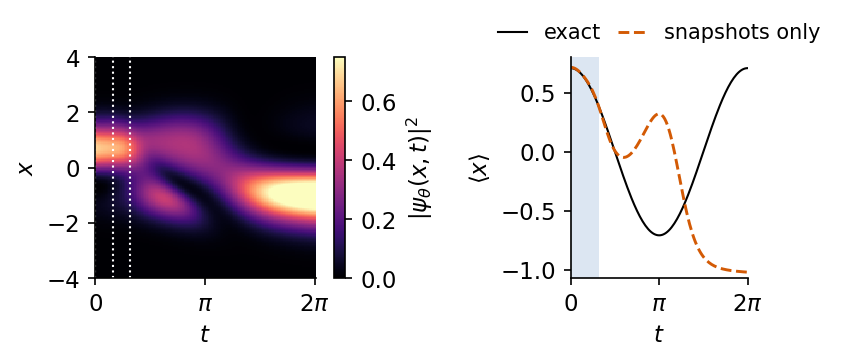

In [13]:
def model_figure(res, color, label, name):
    with mpl.rc_context(SLIDE_RC):
        fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained", gridspec_kw={"width_ratios": [1.25, 1]})
        fig.get_layout_engine().set(wspace=0.08)
        im = density_map(axs[0], res["dens"], snaps=T_SNAP)
        fig.colorbar(im, ax=axs[0], label=r"$|\psi_\theta(x,t)|^2$", pad=0.02)
        ax = axs[1]
        ax.axvspan(0, T_SNAP.max(), color="#DCE6F2", lw=0, zorder=0)
        ax.plot(T_GRID, XM_EX, color=COL["exact"], lw=1.0, label="exact")
        ax.plot(T_GRID, res["xm"], "--", color=color, label=label)
        ax.set_xlabel("$t$"); ax.set_ylabel(r"$\langle x\rangle$"); ax.set_xlim(0, T_MAX)
        ax.set_xticks([0, np.pi, 2 * np.pi]); ax.set_xticklabels(["0", r"$\pi$", r"$2\pi$"])
        ax.set_ylim(min(-0.8, res["xm"].min() - 0.05), max(0.8, res["xm"].max() + 0.05))
        ax.legend(loc="lower center", bbox_to_anchor=(0.5, 0.98), ncol=2, fontsize=10, handlelength=1.4, columnspacing=0.8)
        save(fig, name); plt.show()

model_figure(res_A, COL["data"], "snapshots only", "fig_lab045_data_only")

### Snapshots and the Schrödinger equation

In [14]:
p_B, h_B = train(make_loss(net_env), init_mlp(jax.random.key(0), SIZES))
res_B = evaluate(net_env, p_B)
nums["model_B"] = summary("model B (snapshots + Schrödinger residual)", res_B, h_B)

model B (snapshots + Schrödinger residual): training 73 s, final loss 2.0e-04
   max |psi_theta - psi| for t <= 1: 6.7e-03, for t > 1: 4.0e-03
   max ||psi_theta|^2 - |psi|^2| = 3.6e-03, norm between 0.9993 and 1.0021, max |<x> - cos t/sqrt 2| = 6.4e-03


The PINN takes 73 s to train. Its maximal error is $6.7\times10^{-3}$ inside the observation window and $4.0\times10^{-3}$ for $t>1$, so the error does not grow when the network leaves the data. The density error stays below $3.6\times10^{-3}$ over the whole period, the norm stays between 0.999 and 1.002, and the mean position deviates from $\cos t/\sqrt2$ by at most $6.4\times10^{-3}$. The figure has the layout of the previous one. The density returns to its initial form at $t=2\pi$, and the mean position completes one full oscillation. The times after the last snapshot lie outside the data and inside the space–time window of the collocation points, where the residual is penalised.

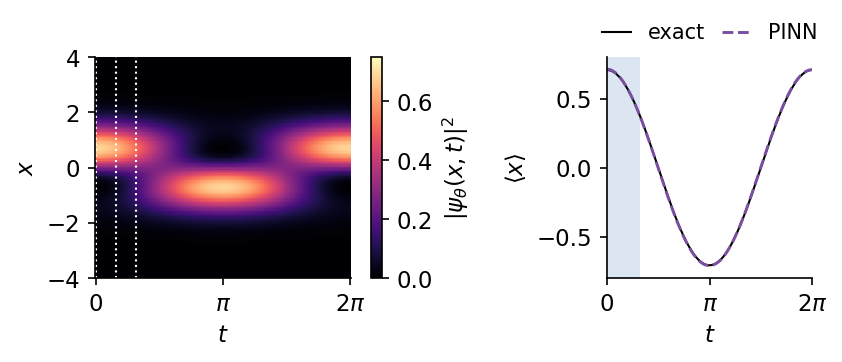

In [15]:
model_figure(res_B, COL["PINN"], "PINN", "fig_lab045_pinn")

### Network without the envelope

We repeat the training of model B with the envelope removed, $(u_\theta,v_\theta)=N_\theta(x,t)$, and keep everything else unchanged.

In [16]:
net_plain = make_net(False)
p_C, h_C = train(make_loss(net_plain), init_mlp(jax.random.key(0), SIZES))
res_C = evaluate(net_plain, p_C)
nums["model_C"] = summary("PINN without envelope", res_C, h_C)

PINN without envelope: training 84 s, final loss 1.2e-03
   max |psi_theta - psi| for t <= 1: 2.7e-02, for t > 1: 3.6e-01
   max ||psi_theta|^2 - |psi|^2| = 4.4e-01, norm between 0.5455 and 0.9942, max |<x> - cos t/sqrt 2| = 4.2e-01


Without the envelope the final loss is $1.3\times10^{-3}$, against $2.0\times10^{-4}$ with it. The error grows from $2.5\times10^{-2}$ inside the observation window to 0.37, and the norm decreases to 0.564 at $t=2\pi$. The residuals are linear in $\psi_\theta$, so a smaller amplitude lowers the residual term, and the loss contains no term that fixes the norm away from the snapshots. The loss of norm is consistent with this freedom, although the experiment does not isolate the mechanism in the optimisation. With the envelope the same loss keeps the norm within the range given above, and we have not separated which property of the envelope is responsible.

The figure compares all models over the period. The left panel shows the largest density error $\max_x\big||\psi_\theta|^2-|\psi|^2\big|$ on a logarithmic axis, together with the two classical references of this section, the split-step propagation of the first snapshot and the expansion in eigenstates. The middle panel shows the norm $N_\theta(t)$ and the right panel the deviation $|\langle x\rangle_\theta(t)-\langle x\rangle(t)|$ of the mean position. The shaded band is the observation window.

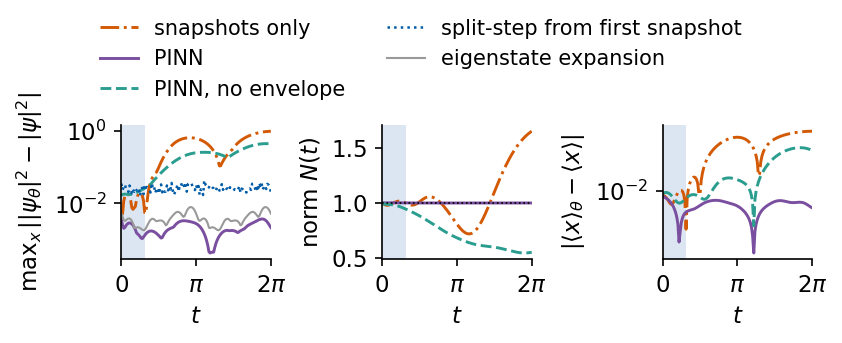

In [17]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.2), layout="constrained")
    runs = ((res_A, COL["data"], "-.", "snapshots only"), (res_B, COL["PINN"], "-", "PINN"),
            (res_C, COL["plain"], "--", "PINN, no envelope"))
    for r, c, ls, lab in runs:
        axs[0].semilogy(T_GRID, r["err_dens"], ls, color=c, label=lab)
        axs[1].plot(T_GRID, r["norm"], ls, color=c)
        axs[2].plot(T_GRID, np.abs(r["xm"] - XM_EX), ls, color=c)
    axs[0].semilogy(T_GRID, np.abs(np.abs(psi_ssf_noisy)**2 - DENS_EX).max(-1), ":", color=COL["SSF"], lw=1.2,
                    label="split-step from first snapshot")
    axs[0].semilogy(T_GRID, np.abs(np.abs(psi_proj)**2 - DENS_EX).max(-1), "-", color="0.6", lw=1.0,
                    label="eigenstate expansion")
    axs[1].axhline(1.0, color="k", lw=0.8, ls=":")
    axs[2].set_yscale("log")
    axs[0].set_ylabel(r"max$_x\,||\psi_\theta|^2-|\psi|^2|$"); axs[1].set_ylabel(r"norm $N(t)$")
    axs[2].set_ylabel(r"$|\langle x\rangle_\theta-\langle x\rangle|$")
    for ax in axs:
        ax.axvspan(0, T_SNAP.max(), color="#DCE6F2", lw=0, zorder=0)
        ax.set_xlabel("$t$"); ax.set_xlim(0, T_MAX)
        ax.set_xticks([0, np.pi, 2 * np.pi]); ax.set_xticklabels(["0", r"$\pi$", r"$2\pi$"])
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=2, fontsize=10, handlelength=1.8)
    save(fig, "fig_lab045_comparison"); plt.show()

The fit to the snapshots and the PINN agree inside the observation window and separate as soon as the data end. The equation of motion in the loss carries the information of the three snapshots through the whole period, and the PINN reaches the accuracy of the eigenstate expansion, $4.0\times10^{-3}$ against $6.1\times10^{-3}$ in the maximal error of $\psi$ for $t>1$. It is more accurate than the split-step propagation of the noisy first snapshot, since it fits all three snapshots at once under the constraint of the equation and thereby averages their noise. The PINN uses the same knowledge as the classical references, the Hamiltonian, and its advantage over model A comes entirely from this knowledge. The envelope builds the spatial decay of bound states into the network. For the tested initialisation and training budget, the run with this envelope follows the full period and the run without it loses norm.

### Energy and phase

The density, the norm and the mean position are all built from $|\psi|^2$ and do not test the phase of the wave function. The energy expectation value
$$E(t)=\frac{1}{N(t)}\int\Big[\tfrac12\,|\partial_x\psi(x,t)|^2+V(x)\,|\psi(x,t)|^2\Big]dx$$
depends on the phase through the kinetic term, and for the exact evolution it is constant, $E=\sum_n|c_n|^2E_n=\tfrac12\cdot\tfrac12+\tfrac12\cdot\tfrac32=1$. We compute $\partial_x\psi$ on the grid with the discrete Fourier transform, $\partial_x\psi=\mathcal F^{-1}[ik\,\mathcal F\psi]$. In addition we compare the real and imaginary parts of $\psi$ at the time $t^*=3\pi/2$, three quarters of the period and far outside the observation window, where the exact wave function is
$$\psi(x,t^*)=\tfrac{1}{\sqrt2}\Big[\phi_0(x)\,e^{-3\pi i/4}+\phi_1(x)\,e^{-9\pi i/4}\Big] .$$

In [18]:
def energy(psi, V):
    # E(t) = int [ |d_x psi|^2 / 2 + V |psi|^2 ] dx / N(t), with d_x psi from the discrete Fourier transform
    dpsi = np.fft.ifft(1j * K * np.fft.fft(psi, axis=-1), axis=-1)
    dens = np.abs(psi)**2
    return (0.5 * np.abs(dpsi)**2 + V * dens).sum(-1) / dens.sum(-1)

V_HO = 0.5 * X**2
E_EX = energy(PSI_EX, V_HO)
I_STAR = 96                                     # T_GRID[96] = 3 pi / 2
T_STAR = T_GRID[I_STAR]
print(f"exact evolution: max |E(t) - 1| = {np.abs(E_EX - 1).max():.1e}")
for r, name in ((res_A, "snapshots only"), (res_B, "PINN")):
    r["energy"] = energy(r["psi"], V_HO)
    print(f"{name}: E(t) between {r['energy'].min():.3f} and {r['energy'].max():.3f}, "
          f"max_x |psi_theta - psi| at t* = 3 pi/2: {r['err'][I_STAR]:.1e}")
nums["energy"] = dict(exact_dev=float(np.abs(E_EX - 1).max()),
                      data_min=float(res_A["energy"].min()), data_max=float(res_A["energy"].max()),
                      pinn_dev=float(np.abs(res_B["energy"] - 1).max()),
                      err_star_data=float(res_A["err"][I_STAR]), err_star_pinn=float(res_B["err"][I_STAR]))

exact evolution: max |E(t) - 1| = 3.2e-13
snapshots only: E(t) between 0.671 and 1.433, max_x |psi_theta - psi| at t* = 3 pi/2: 7.8e-01
PINN: E(t) between 0.999 and 1.002, max_x |psi_theta - psi| at t* = 3 pi/2: 2.8e-03


The exact energy equals 1 to within $3.2\times10^{-13}$ on the grid. The PINN keeps $E(t)$ between 0.999 and 1.002 over the whole period, although energy conservation appears nowhere in its loss. The snapshots-only network has the correct energy only near the data, and later its $E(t)$ swings between 0.671 and 1.433. At $t^*=3\pi/2$ the largest error of the PINN wave function is $2.8\times10^{-3}$, against 0.78 for the snapshots-only network. The left panel of the figure shows $E(t)$ with the observation window shaded. The middle and right panels show the real part and the imaginary part of $\psi(x,t^*)$ for the exact solution and for both networks. The PINN reproduces both parts and thereby the phase of the wave function, which the density alone leaves untested.

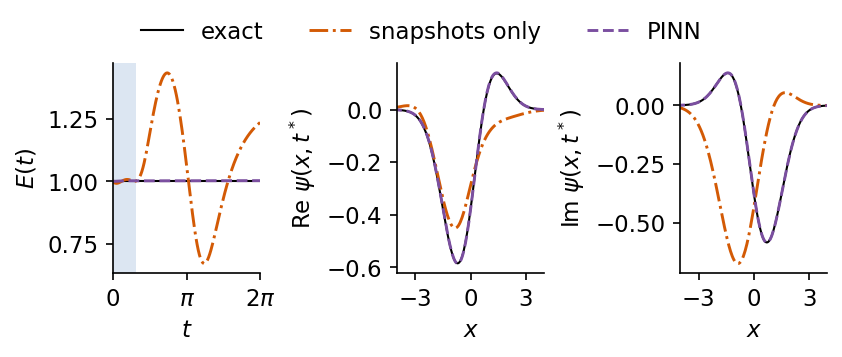

In [19]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.3), layout="constrained")
    ax = axs[0]
    ax.axvspan(0, T_SNAP.max(), color="#DCE6F2", lw=0, zorder=0)
    ax.plot(T_GRID, E_EX, color=COL["exact"], lw=1.0, label="exact")
    ax.plot(T_GRID, res_A["energy"], "-.", color=COL["data"], label="snapshots only")
    ax.plot(T_GRID, res_B["energy"], "--", color=COL["PINN"], label="PINN")
    ax.set_xlabel("$t$"); ax.set_ylabel("$E(t)$"); ax.set_xlim(0, T_MAX)
    ax.set_xticks([0, np.pi, 2 * np.pi]); ax.set_xticklabels(["0", r"$\pi$", r"$2\pi$"])
    for ax, part, lab in ((axs[1], np.real, r"Re $\psi(x,t^*)$"), (axs[2], np.imag, r"Im $\psi(x,t^*)$")):
        ax.plot(X, part(PSI_EX[I_STAR]), color=COL["exact"], lw=1.0)
        ax.plot(X, part(res_A["psi"][I_STAR]), "-.", color=COL["data"])
        ax.plot(X, part(res_B["psi"][I_STAR]), "--", color=COL["PINN"])
        ax.set_xlim(-4, 4); ax.set_xticks([-3, 0, 3]); ax.set_xlabel("$x$"); ax.set_ylabel(lab)
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=3, handlelength=1.8)
    save(fig, "fig_lab045_energy_phase"); plt.show()

<hr/>
## 4. Number of snapshots and noise

The experiment above used three snapshots with noise $\sigma=0.01$. We now vary both. The snapshots are taken at the times $t_k=0,0.5,1,\dots$ with spacing 0.5, and we use the first 1, 2, 3 or 5 of them, so that the data reach up to $t=0$, 0.5, 1 or 2. A single snapshot at $t=0$ is the initial condition of the Schrödinger equation. For each set we train the snapshots-only network and the PINN and record the largest error $\max_{x,t}|\psi_\theta-\psi|$ over the whole window $0\le t\le2\pi$. With three snapshots we further train the PINN on data with the noise levels $\sigma=0$, 0.01 and 0.05. To keep the runtime short, every training run of this section uses 3000 Adam steps and 1000 L-BFGS iterations, half the budget of the runs above, with the same learning-rate schedule, network, collocation points and initial parameters. The noise of each data set is drawn with the same random seed as above, so the three-snapshot data at $\sigma=0.01$ coincide with the snapshots of the previous section.

In [20]:
N_ADAM_SCAN, N_LBFGS_SCAN = 3000, 1000

def make_snapshots(t_snap, sigma, seed=0):
    # noisy snapshots of the exact wave function at the times t_snap, as arrays for the loss
    r_ = np.random.default_rng(seed)
    s = psi_exact(X[I_DATA][None, :], t_snap[:, None])
    s = s + sigma * (r_.normal(size=s.shape) + 1j * r_.normal(size=s.shape))
    xd, td = np.meshgrid(X[I_DATA], t_snap)
    return (jnp.asarray(xd.ravel(), F32), jnp.asarray(td.ravel(), F32),
            jnp.asarray(np.stack([s.real.ravel(), s.imag.ravel()], 1), F32))

print("three snapshots at sigma = 0.01 reproduce the data above:",
      bool(jnp.all(make_snapshots(T_SNAP, SIGMA)[2] == UV_D)))
SCAN_SNAPS = {1: [0.0], 2: [0.0, 0.5], 3: [0.0, 0.5, 1.0], 5: [0.0, 0.5, 1.0, 1.5, 2.0]}
scan_rows, res_noise = [], {}
for n, ts in SCAN_SNAPS.items():
    data = make_snapshots(np.array(ts), SIGMA)
    row = dict(n=n, reach=ts[-1])
    for tag, w_r in (("data", 0.0), ("pinn", 1.0)):
        p, h = train(make_loss(net_env, w_r=w_r, data=data), init_mlp(jax.random.key(0), SIZES),
                     n_adam=N_ADAM_SCAN, n_lbfgs=N_LBFGS_SCAN)
        r = evaluate(net_env, p)
        row[tag] = float(r["err"].max()); row[tag + "_time"] = h["time"]
        if tag == "pinn" and n == 3:
            res_noise[SIGMA] = r
    scan_rows.append(row)
    print(f"{n} snapshot(s) up to t = {ts[-1]:g}: max error snapshots only {row['data']:.1e}, "
          f"PINN {row['pinn']:.1e} ({row['pinn_time']:.0f} s)")
for sigma in (0.0, 0.05):
    p, h = train(make_loss(net_env, data=make_snapshots(T_SNAP, sigma)), init_mlp(jax.random.key(0), SIZES),
                 n_adam=N_ADAM_SCAN, n_lbfgs=N_LBFGS_SCAN)
    res_noise[sigma] = evaluate(net_env, p)
noise_rows = [dict(sigma=s, err=float(res_noise[s]["err"].max()), norm_min=float(res_noise[s]["norm"].min()),
                   norm_max=float(res_noise[s]["norm"].max())) for s in (0.0, SIGMA, 0.05)]
for row in noise_rows:
    print(f"PINN, three snapshots, sigma = {row['sigma']:g}: max error {row['err']:.1e}, "
          f"norm between {row['norm_min']:.3f} and {row['norm_max']:.3f}")
nums["scan"] = scan_rows; nums["noise"] = noise_rows

three snapshots at sigma = 0.01 reproduce the data above: True


1 snapshot(s) up to t = 0: max error snapshots only 1.1e+00, PINN 2.2e-02 (39 s)


2 snapshot(s) up to t = 0.5: max error snapshots only 1.9e+00, PINN 2.0e-02 (40 s)


3 snapshot(s) up to t = 1: max error snapshots only 1.5e+00, PINN 7.0e-03 (40 s)


5 snapshot(s) up to t = 2: max error snapshots only 1.5e+00, PINN 7.9e-03 (40 s)


PINN, three snapshots, sigma = 0: max error 7.8e-03, norm between 0.994 and 1.000
PINN, three snapshots, sigma = 0.01: max error 7.0e-03, norm between 0.992 and 1.002
PINN, three snapshots, sigma = 0.05: max error 3.1e-02, norm between 0.991 and 1.012


The snapshots-only network fails for every data set, with a largest error between 1.1 and 1.9, because nothing in its loss constrains the function after the last snapshot. The PINN reaches $2.2\times10^{-2}$ with the single snapshot at $t=0$ and $2.0\times10^{-2}$ with two snapshots. With three and five snapshots it reaches $7.0\times10^{-3}$ and $7.9\times10^{-3}$. A noiseless snapshot of the full complex wave function fixes an initial condition, and minimising the Schrödinger residual constrains its continuation through the period. Further snapshots average the noise of the data and lower the error by a factor of about 3, and beyond three snapshots we see no further gain at this training budget. For comparison, model B of Section 3 with the full budget reaches $6.7\times10^{-3}$ over the whole window with the same three snapshots.

The noise scan shows the same balance. Without noise the PINN reaches $7.8\times10^{-3}$, close to the $7.0\times10^{-3}$ at $\sigma=0.01$, so at this noise level the error is set by the training. At $\sigma=0.05$ the error grows to $3.1\times10^{-2}$. The left panel of the figure shows the largest error $\max_{x,t}|\psi_\theta-\psi|$ over the window against the number of snapshots, taken at the times $0,0.5,1,1.5,2$ in this order. The right panel shows $\max_x|\psi_\theta-\psi|$ at each time for the three noise levels with the observation window shaded. At $\sigma=0.05$ the error is largest at the snapshots, where the network partly follows the noise, and it is smaller later. At the two lower noise levels the error grows slowly towards the end of the window.

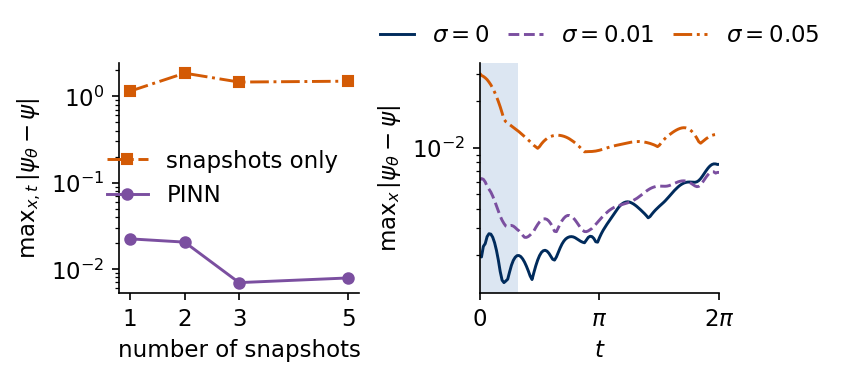

In [21]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained")
    ax = axs[0]
    ns = [r["n"] for r in scan_rows]
    ax.semilogy(ns, [r["data"] for r in scan_rows], "s-.", color=COL["data"], ms=5, label="snapshots only")
    ax.semilogy(ns, [r["pinn"] for r in scan_rows], "o-", color=COL["PINN"], ms=5, label="PINN")
    ax.set_xticks(ns)
    ax.set_xlabel("number of snapshots"); ax.set_ylabel(r"max$_{x,t}\,|\psi_\theta-\psi|$")
    ax.legend(loc="center right", handlelength=1.8)
    ax = axs[1]
    ax.axvspan(0, T_SNAP.max(), color="#DCE6F2", lw=0, zorder=0)
    for s, ls, c in ((0.0, "-", UJNavy), (SIGMA, "--", COL["PINN"]), (0.05, "-.", DSOrange)):
        ax.semilogy(T_GRID, res_noise[s]["err"], ls, color=c, label=rf"$\sigma={s:g}$")
    ax.set_xlabel("$t$"); ax.set_ylabel(r"max$_x\,|\psi_\theta-\psi|$"); ax.set_xlim(0, T_MAX)
    ax.set_xticks([0, np.pi, 2 * np.pi]); ax.set_xticklabels(["0", r"$\pi$", r"$2\pi$"])
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 0.98), ncol=3, handlelength=1.5, columnspacing=0.8)
    save(fig, "fig_lab045_scans"); plt.show()

<hr/>
## 5. Cost

For the forward problem with a known initial state the natural tool is the classical solver. The cell compares the split-step reference run with the training of model B. The solver receives the exact initial state and is scored at the final time, while the PINN fits noisy snapshots and is scored by its largest error after the last snapshot, so the comparison concerns the order of magnitude of the cost of two different tasks. Wall times depend on the hardware and on the load of the machine.

In [22]:
row = [r for r in ssf_rows if r["n"] == 1024][0]
nums["cost"] = dict(ssf_dt=row["dt"], ssf_err=row["err"], ssf_time=row["time"], pinn_time=h_B["time"],
                    pinn_err=nums["model_B"]["err_out"])
print(f"split-step, dt = {row['dt']:.4f}: error {row['err']:.1e} in {row['time']:.1e} s")
print(f"PINN (model B): error {nums['model_B']['err_out']:.1e} after {h_B['time']:.0f} s of training,"
      f" ratio of times {h_B['time'] / row['time']:.0e}")

split-step, dt = 0.0061: error 8.4e-06 in 9.1e-03 s
PINN (model B): error 4.0e-03 after 73 s of training, ratio of times 8e+03


The split-step solver with 1024 steps reaches $8.4\times10^{-6}$ in $7.5\times10^{-3}$ s. The PINN reaches $4.0\times10^{-3}$ after 73 s of training, a factor of about $8\times10^{3}$ longer for an error that is more than two orders of magnitude larger. These error and timing figures use the different inputs and evaluation times described above. For the trapped particle with a known initial state the split-step solver is faster and more accurate by a wide margin. The PINN does not need an initial state on the full grid or a time-stepping scheme, and it combines scattered, noisy data with the equation in a single fit. The next section uses this property for a parameter of the Hamiltonian.

<hr/>
## 6. Unknown trap frequency

We now assume that the trap frequency $\omega$ in $V(x)=\tfrac12\omega^2x^2$ is unknown, while lengths and times keep the units of the true trap with $\omega=1$. The PINN treats $\omega$ like a weight of the network. We write $\omega=e^s$, train $s$ together with $\theta$ on the loss of model B with the trainable potential, and start from $\omega=1.5$. The data are the same three noisy snapshots.

The classical reference is a least-squares fit through the split-step solver. For a trial $\omega$ we propagate the first snapshot with $\Delta t=0.01$ and compare the result with the two later snapshots,
$$\chi^2(\omega)=\sum_{k\,:\,t_k>0}\ \sum_j\big|\psi_{\rm SSF}(x_j,t_k;\omega)-\psi_{jk}\big|^2,$$
and minimise $\chi^2$ over $0.5\le\omega\le2$ with the bounded scalar minimiser of `scipy.optimize.minimize_scalar`. Repeating the least-squares estimate for 20 further noise realisations gives its statistical spread.

In [23]:
OMEGA_INIT = 1.5

# PINN with trainable omega = exp(log omega), same snapshots, network and budget as model B
q0 = (init_mlp(jax.random.key(0), SIZES), jnp.log(jnp.asarray(OMEGA_INIT, F32)))
q_inv, h_inv = train(make_loss(net_env, learn_omega=True), q0, monitor=lambda q: float(jnp.exp(q[1])))
om_pinn = float(jnp.exp(q_inv[1]))

# least squares through the split-step solver: propagate the noisy snapshot at t = 0, compare at t = 0.5 and 1.0
def ls_objective(omega, snaps, dt=0.01):
    p0 = np.interp(X, X[I_DATA], snaps[0].real) + 1j * np.interp(X, X[I_DATA], snaps[0].imag)
    n = int(round(T_SNAP.max() / dt))
    psis = np.asarray(split_step(p0, T_SNAP.max() / n, n, omega))
    idx = np.round(T_SNAP / (T_SNAP.max() / n)).astype(int)
    return float(sum(np.sum(np.abs(psis[i][I_DATA] - snaps[k])**2) for k, i in enumerate(idx) if k > 0))

om_ls = minimize_scalar(ls_objective, bounds=(0.5, 2.0), args=(psi_snap,), method="bounded").x
# spread of the least-squares estimate over independent noise realisations of the snapshots
om_ls_rep = []
psi_clean = psi_exact(X[I_DATA][None, :], T_SNAP[:, None])
for seed in range(1, 21):
    r_ = np.random.default_rng(seed)
    s_ = psi_clean + SIGMA * (r_.normal(size=psi_clean.shape) + 1j * r_.normal(size=psi_clean.shape))
    om_ls_rep.append(minimize_scalar(ls_objective, bounds=(0.5, 2.0), args=(s_,), method="bounded").x)
om_ls_rep = np.array(om_ls_rep)
res_inv = evaluate(net_env, q_inv[0])
print(f"true omega = 1, start {OMEGA_INIT}: PINN {om_pinn:.4f} after {h_inv['time']:.0f} s, least squares {om_ls:.4f}")
print(f"least squares over 20 further noise realisations: mean {om_ls_rep.mean():.4f}, std {om_ls_rep.std(ddof=1):.4f}")
print(f"inverse PINN: max |psi_theta - psi| over [0, 2 pi] = {res_inv['err'].max():.1e}")
nums["inverse"] = dict(omega_init=OMEGA_INIT, omega_pinn=om_pinn, omega_ls=float(om_ls), ls_mean=float(om_ls_rep.mean()),
                       ls_std=float(om_ls_rep.std(ddof=1)), time=h_inv["time"], err=float(res_inv["err"].max()))

true omega = 1, start 1.5: PINN 0.9952 after 76 s, least squares 0.9962
least squares over 20 further noise realisations: mean 1.0000, std 0.0033
inverse PINN: max |psi_theta - psi| over [0, 2 pi] = 1.9e-02


The PINN estimate moves from 1.5 to below 1 during the Adam stage and approaches the true value under L-BFGS, as the left panel of the figure shows (iterations on the horizontal axis, the switch to L-BFGS dotted). The right panel shows $\chi^2(\omega)$ for the first noise realisation with the least-squares minimum and the PINN estimate as vertical lines.

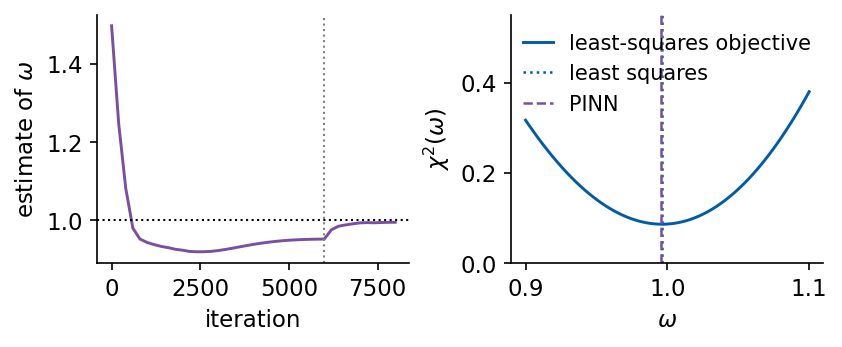

In [24]:
om_scan = np.linspace(0.9, 1.1, 81)
obj = np.array([ls_objective(w, psi_snap) for w in om_scan])
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.2), layout="constrained")
    ax = axs[0]
    ax.plot(h_inv["it"], h_inv["mon"], color=COL["PINN"])
    ax.axhline(1.0, color="k", ls=":", lw=1.0); ax.axvline(6000, color="0.5", ls=":", lw=1.0)
    ax.set_xlabel("iteration"); ax.set_ylabel(r"estimate of $\omega$")
    ax = axs[1]
    ax.plot(om_scan, obj, color=COL["SSF"], label="least-squares objective")
    ax.axvline(om_ls, color=COL["SSF"], ls=":", lw=1.2, label="least squares")
    ax.axvline(om_pinn, color=COL["PINN"], ls="--", lw=1.2, label="PINN")
    ax.set_xlabel(r"$\omega$"); ax.set_ylabel(r"$\chi^2(\omega)$"); ax.set_ylim(0, 1.45 * obj.max())
    ax.legend(loc="upper center", fontsize=10, handlelength=1.4)
    save(fig, "fig_lab045_inverse"); plt.show()

On the first noise realisation the PINN gives $\omega=0.9952$ after 76 s and the least-squares fit $\omega=0.9962$. Over 20 further realisations the least-squares estimates have the mean 1.0000 and the standard deviation 0.0033, so the PINN estimate lies within 1.5 standard deviations of the true value. Its wave function deviates from the exact one by at most $1.9\times10^{-2}$ over the period. The least-squares fit evaluates the classical solver for each trial frequency, and the PINN obtains the frequency and the full evolution from one training. For this one-parameter problem the two estimates agree within the statistical spread of the least-squares fit.

<hr/>
## 7. Tunnelling in a double well

The second example is a particle in the symmetric double well
$$V(x)=V_0\Big(\frac{x^2}{a^2}-1\Big)^2,$$
with two minima $V=0$ at $x=\pm a$ separated by a barrier of height $V_0$ at $x=0$. We keep $\hbar=m_0=1$ and the box of Example 1, and choose $a=1$ and $V_0=4$. Near each minimum the potential is approximately harmonic, $V\approx\tfrac12\omega_w^2(x\mp a)^2$ with the well frequency $\omega_w=\sqrt{8V_0}/a$.

The lowest eigenstates are computed numerically. Besides the three-point finite-difference Hamiltonian of Section 1 we diagonalise the Fourier-grid Hamiltonian
$$H=\mathcal F^{-1}\,\mathrm{diag}\big(p^2/2\big)\,\mathcal F+\mathrm{diag}\big(V(x_j)\big),$$
whose kinetic term is the multiplication by $p^2/2$ in Fourier space used by the split-step method, so that its eigenstates are stationary under the split-step propagation up to the time-step error. The same diagonalisation on a grid of 512 points checks the convergence in $\Delta x$.

When the barrier is high, the two lowest states form a doublet. The ground state $\phi_+$ is even and has no node, the first excited state $\phi_-$ is odd with a node at $x=0$, and their energies differ by the tunnelling splitting $\Delta E=E_1-E_0$, which decreases exponentially with the height and width of the barrier [L. D. Landau, E. M. Lifshitz, *Quantum Mechanics: Non-Relativistic Theory*, 3rd ed., Pergamon (1977), [doi:10.1016/C2013-0-02793-4](https://doi.org/10.1016/C2013-0-02793-4)]. The next state lies far above the doublet. The combinations
$$\phi_L=\frac{\phi_++\phi_-}{\sqrt2},\qquad \phi_R=\frac{\phi_+-\phi_-}{\sqrt2}$$
are localised in the left and in the right well, with the signs fixed so that $\phi_\pm>0$ in the left well. They evolve in time. A small fraction
$$P_R(0)=\int_{x>0}\phi_L(x)^2\,dx$$
of the probability of $\phi_L$ lies in the right well, and on the grid the point $x=0$ enters this integral with half weight.

In [25]:
A_DW, V0_DW = 1.0, 4.0                          # minima at +-a, barrier height V0

def v_dw(x, v0=V0_DW):
    return v0 * (x**2 / A_DW**2 - 1)**2

def fourier_hamiltonian(v, n=N_X):
    # H = F^-1 diag(k^2/2) F + diag(V) on the periodic grid of n points in [-L, L)
    x = -L_BOX + 2 * L_BOX * np.arange(n) / n
    k = 2 * np.pi * np.fft.fftfreq(n, d=2 * L_BOX / n)
    kin = np.fft.ifft(0.5 * k[:, None]**2 * np.fft.fft(np.eye(n), axis=0), axis=0).real
    return kin + np.diag(v(x))

H_fd_dw = (np.diag(1 / DX**2 + v_dw(X)) - np.diag(np.full(N_X - 1, 0.5 / DX**2), 1)
           - np.diag(np.full(N_X - 1, 0.5 / DX**2), -1))
E_fd_dw = np.linalg.eigvalsh(H_fd_dw)[:3]
E_DW, U_DW = np.linalg.eigh(fourier_hamiltonian(v_dw))
E_512 = np.linalg.eigvalsh(fourier_hamiltonian(v_dw, n=512))[:3]
PHI_P, PHI_M = U_DW[:, 0] / np.sqrt(DX), U_DW[:, 1] / np.sqrt(DX)       # normalised to int phi^2 dx = 1
PHI_P *= np.sign(PHI_P.sum()); PHI_M *= np.sign(PHI_M[X < 0].sum())    # phi_+ > 0, phi_- > 0 in the left well
PHI_L, PHI_R = (PHI_P + PHI_M) / np.sqrt(2), (PHI_P - PHI_M) / np.sqrt(2)
DE = E_DW[1] - E_DW[0]; E_BAR = 0.5 * (E_DW[0] + E_DW[1]); T_TUN = 2 * np.pi / DE
W_R = (X > 0) + 0.5 * (X == 0)                  # grid weights of int_{x>0}, half weight at x = 0
P_R0 = float(np.sum(W_R * PHI_L**2) * DX)
X_TURN = A_DW * np.sqrt(1 + np.array([-1, 1]) * np.sqrt(E_BAR / V0_DW))   # V(x) = E_bar in the right well
print("finite differences:", np.round(E_fd_dw, 4))
print("Fourier grid, 256 points:", np.round(E_DW[:3], 4), "| 512 points:", np.round(E_512, 4))
print(f"Delta E = {DE:.4f}, T_tun = 2 pi / Delta E = {T_TUN:.3f}, E_2 - E_1 = {E_DW[2] - E_DW[1]:.3f}, "
      f"well frequency {np.sqrt(8 * V0_DW) / A_DW:.3f}")
print(f"P_R(0) = int_(x>0) phi_L^2 dx = {P_R0:.4f}; mean energy of the doublet {E_BAR:.4f} < V0 = {V0_DW:g}; "
      f"classical turning points of the right well {X_TURN[0]:.3f}, {X_TURN[1]:.3f}")
print(f"max |phi_+-(+-L)| = {max(abs(PHI_P[0]), abs(PHI_M[0])):.1e}")
nums["dw"] = dict(a=A_DW, V0=V0_DW, E_fd=E_fd_dw.tolist(), E=E_DW[:3].tolist(), E_512=E_512.tolist(), dE=DE,
                  T_tun=T_TUN, E_bar=E_BAR, gap=E_DW[2] - E_DW[1], p=P_R0, x_turn=X_TURN.tolist(),
                  omega_w=float(np.sqrt(8 * V0_DW) / A_DW))

finite differences: [2.2885 2.7501 5.9362]
Fourier grid, 256 points: [2.2896 2.7521 5.9414] | 512 points: [2.2896 2.7521 5.9414]
Delta E = 0.4624, T_tun = 2 pi / Delta E = 13.587, E_2 - E_1 = 3.189, well frequency 5.657
P_R(0) = int_(x>0) phi_L^2 dx = 0.0216; mean energy of the doublet 2.5209 < V0 = 4; classical turning points of the right well 0.454, 1.339
max |phi_+-(+-L)| = 1.4e-17


The finite-difference Hamiltonian gives the lowest energies 2.2885, 2.7501 and 5.9362. The Fourier-grid Hamiltonian gives 2.2896, 2.7521 and 5.9414 on both grids of 256 and 512 points, so these energies are converged to the four digits shown, and the three-point formula deviates from them by up to $5\times10^{-3}$. The splitting is $\Delta E=0.4624$, which gives the tunnelling period $T_{\rm tun}=2\pi/\Delta E=13.587$, more than twice the window of Example 1. The next state lies $E_2-E_1=3.189$ above the doublet, about seven times the splitting. Both energies of the doublet lie below the barrier $V_0=4$, and the well frequency is $\omega_w=5.657$. The state $\phi_L$ has the weight $p=0.0216$ in the right well, and the eigenstates are below $10^{-17}$ at the edges of the box. As in the trap, the finite-difference operator assumes zero values outside the box and the Fourier-grid operator is periodic, and with such small tails this difference of boundary conditions has no effect on the digits shown. The left panel of the figure shows the potential with the energies $E_0$ (blue), $E_1$ (orange) and $E_2$ (grey) as horizontal lines. The right panel shows the eigenfunctions $\phi_+$ and $\phi_-$ and the left-localised combination $\phi_L$.

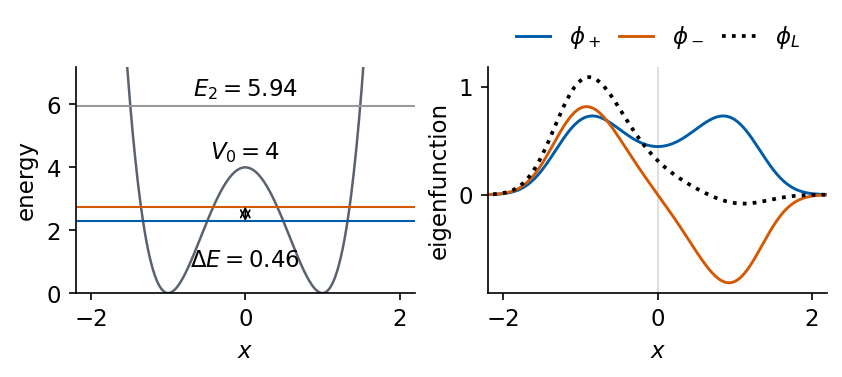

In [26]:
xx = np.linspace(-2.2, 2.2, 400)
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained")
    ax = axs[0]
    ax.plot(xx, v_dw(xx), color=UJGray, lw=1.2)
    for n, c in zip(range(3), (UJBlue, DSOrange, "0.6")):
        ax.plot([-2.2, 2.2], [E_DW[n]] * 2, color=c, lw=1.0)
    ax.text(0, E_DW[2] + 0.15, f"$E_2={E_DW[2]:.2f}$", ha="center", va="bottom")
    ax.annotate("", xy=(0, E_DW[1]), xytext=(0, E_DW[0]), arrowprops=dict(arrowstyle="<->", color="k", lw=0.8,
                shrinkA=0, shrinkB=0))
    ax.text(0, 1.05, rf"$\Delta E={DE:.2f}$", va="center", ha="center")
    ax.text(0, V0_DW + 0.1, f"$V_0={V0_DW:g}$", va="bottom", ha="center")
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(0, 7.2); ax.set_xlabel("$x$"); ax.set_ylabel("energy")
    ax = axs[1]
    ax.plot(X, PHI_P, color=UJBlue, label=r"$\phi_+$")
    ax.plot(X, PHI_M, color=DSOrange, label=r"$\phi_-$")
    ax.plot(X, PHI_L, ":", color="k", lw=1.8, label=r"$\phi_L$")
    ax.axvline(0, color="0.85", lw=0.8, zorder=0)
    ax.set_xlim(-2.2, 2.2); ax.set_xlabel("$x$"); ax.set_ylabel("eigenfunction")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 0.98), ncol=3, handlelength=1.5, columnspacing=0.8)
    save(fig, "fig_lab045_dw_potential"); plt.show()

### Tunnelling oscillation

We prepare the particle in the left well, $\psi(x,0)=\phi_L(x)$, and shift the zero of energy to the mean energy of the doublet, $\bar E=(E_0+E_1)/2$. Subtracting $\bar E$ from the potential multiplies the wave function by the spatially uniform phase $e^{i\bar Et}$. The density and the expectation value of every observable other than the Hamiltonian are unchanged, while the energy expectation value shifts by $-\bar E$, since the Hamiltonian itself has changed. In this frame the two components carry the phases $e^{\pm i\Delta Et/2}$, and
$$\psi(x,t)=\frac{\phi_+(x)\,e^{i\Delta Et/2}+\phi_-(x)\,e^{-i\Delta Et/2}}{\sqrt2}=\cos\frac{\Delta E\,t}{2}\,\phi_L(x)+i\,\sin\frac{\Delta E\,t}{2}\,\phi_R(x) .$$
The real part of $\psi$ sits in the left well and the imaginary part in the right one. The density $|\psi|^2=\cos^2(\Delta Et/2)\,\phi_L^2+\sin^2(\Delta Et/2)\,\phi_R^2$ moves from the left to the right well within the time $\pi/\Delta E$ and returns after the tunnelling period
$$T_{\rm tun}=\frac{2\pi}{\Delta E} .$$
The probability of finding the particle in the right well,
$$P_R(t)=\int_{x>0}|\psi(x,t)|^2\,dx=P_R(0)+\big[1-2P_R(0)\big]\,\sin^2\frac{\Delta E\,t}{2},$$
follows from the mirror symmetry $\phi_R(x)=\phi_L(-x)$. In the two-state approximation, where $\phi_L$ is taken to be completely localised in the left well, $P_R(0)=0$ and $P_R(t)=\sin^2(\Delta Et/2)$. For our potential the approximation is off by at most $P_R(0)$. The mean position is $\langle x\rangle(t)=\langle x\rangle_L\cos(\Delta Et)$ with $\langle x\rangle_L=\int x\,\phi_L^2\,dx$, and the norm is 1.

The mean energy $\bar E$ of the state lies below the barrier. A classical particle with this energy moves between the two turning points of one well and never reaches the other side, so its $P_R$ is either 0 or 1 for all times. Tunnelling through the barrier has no classical counterpart.

The exact evolution on the grid follows from the formula above, since $\phi_L$ contains only the two eigenstates of the Fourier-grid Hamiltonian. We evaluate it at 129 equally spaced times in $0\le t\le T_{\rm tun}$ and check it with the split-step solver, 2048 steps over one tunnelling period with the shifted potential $V(x)-\bar E$.

In [27]:
T_DW = np.linspace(0, T_TUN, 129)              # times of all double-well diagnostics
V_S = v_dw(X) - E_BAR                           # potential with the energy zero at E_bar

def psi_dw_exact(t):
    # cos(Delta E t/2) phi_L + i sin(Delta E t/2) phi_R on the grid, for an array of times
    t = np.asarray(t, float)[..., None]
    return np.cos(DE * t / 2) * PHI_L + 1j * np.sin(DE * t / 2) * PHI_R

def diagnostics_dw(psi):
    # density, norm, probability in the right well and mean position
    dens = np.abs(psi)**2
    norm = dens.sum(-1) * DX
    return dens, norm, (dens * W_R).sum(-1) * DX, (dens * X).sum(-1) * DX / norm

PSI_DW = psi_dw_exact(T_DW)
DENS_DW, NORM_DW, PR_DW, XM_DW = diagnostics_dw(PSI_DW)
PR_2STATE = np.sin(DE * T_DW / 2)**2
N_SSF_DW = 2048
psi_ssf_dw = np.asarray(split_step(PHI_L, T_TUN / N_SSF_DW, N_SSF_DW, V=jnp.asarray(V_S)))[::N_SSF_DW // 128]
err_ssf_dw = np.abs(psi_ssf_dw - PSI_DW).max()
_, norm_ssf_dw, pr_ssf_dw, _ = diagnostics_dw(psi_ssf_dw)
xm_L = float((PHI_L**2 * X).sum() * DX)
print(f"P_R: max {PR_DW.max():.4f} at t = {T_DW[PR_DW.argmax()]:.3f} (T_tun/2 = {T_TUN / 2:.3f}), "
      f"max |P_R - sin^2(Delta E t/2)| = {np.abs(PR_DW - PR_2STATE).max():.4f}")
print(f"<x>_L = {xm_L:.4f}, max |<x>(t) - <x>_L cos(Delta E t)| = {np.abs(XM_DW - xm_L * np.cos(DE * T_DW)).max():.1e}")
print(f"split-step, dt = {T_TUN / N_SSF_DW:.4f}: max |psi_SSF - psi| over one period {err_ssf_dw:.1e}, "
      f"max |N - 1| {np.abs(norm_ssf_dw - 1).max():.1e}, max |P_R,SSF - P_R| {np.abs(pr_ssf_dw - PR_DW).max():.1e}")
nums["dw"].update(pr_max=float(PR_DW.max()), two_state_dev=float(np.abs(PR_DW - PR_2STATE).max()), xm_L=xm_L,
                  ssf_dt=T_TUN / N_SSF_DW, ssf_err=float(err_ssf_dw), ssf_drift=float(np.abs(norm_ssf_dw - 1).max()))

P_R: max 0.9784 at t = 6.794 (T_tun/2 = 6.794), max |P_R - sin^2(Delta E t/2)| = 0.0216
<x>_L = -0.8131, max |<x>(t) - <x>_L cos(Delta E t)| = 5.1e-14
split-step, dt = 0.0066: max |psi_SSF - psi| over one period 2.0e-03, max |N - 1| 1.0e-13, max |P_R,SSF - P_R| 2.2e-04


The probability in the right well reaches its maximum $1-p=0.9784$ at $t=T_{\rm tun}/2=6.794$. It deviates from the two-state formula $\sin^2(\Delta Et/2)$ by $p\cos(\Delta Et)$, at most $p=0.0216$ at the beginning, the middle and the end of the period. The mean position starts at $\langle x\rangle_L=-0.8131$ and follows $\langle x\rangle_L\cos(\Delta Et)$ to round-off. The split-step solver with $\Delta t=0.0066$ reproduces the wave function to $2.0\times10^{-3}$ over one period, conserves the norm to $1.3\times10^{-13}$ and gives $P_R$ to $2.2\times10^{-4}$.

The left panel of the figure shows the exact density $|\psi(x,t)|^2$ in the plane of time and position. The particle is in the left well at $t=0$ and $t=T_{\rm tun}$ and in the right well at $T_{\rm tun}/2$. The right panel shows $P_R(t)$, the two-state formula and the value $P_R=0$ of a classical particle that starts in the left well with an energy below the barrier.

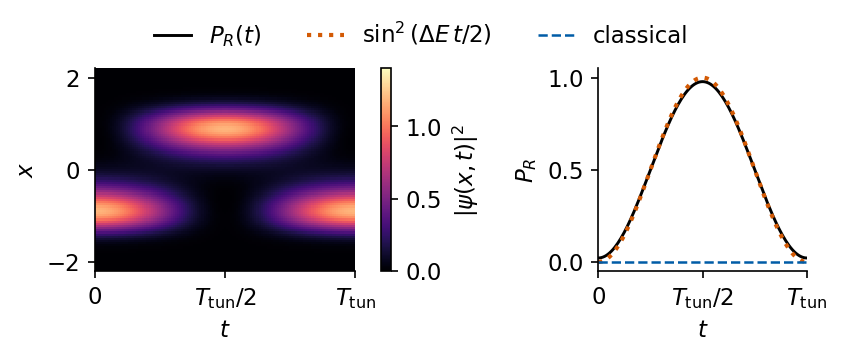

In [28]:
def tun_ticks(ax):
    ax.set_xticks([0, T_TUN / 2, T_TUN]); ax.set_xticklabels(["0", r"$T_{\rm tun}/2$", r"$T_{\rm tun}$"])
    ax.set_xlim(0, T_TUN)

def density_map_dw(ax, dens, snaps=None, vmax=1.4):
    im = ax.pcolormesh(T_DW, X, dens.T, cmap="magma", vmin=0, vmax=vmax, shading="auto", rasterized=True)
    for tk in (snaps if snaps is not None else []):
        ax.axvline(tk, color="w", ls=":", lw=1.0)
    ax.set_ylim(-2.2, 2.2); ax.set_xlabel("$t$"); ax.set_ylabel("$x$"); tun_ticks(ax)
    return im

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained", gridspec_kw={"width_ratios": [1.25, 1]})
    fig.get_layout_engine().set(wspace=0.08)
    im = density_map_dw(axs[0], DENS_DW)
    fig.colorbar(im, ax=axs[0], label=r"$|\psi(x,t)|^2$", pad=0.02)
    ax = axs[1]
    ax.plot(T_DW, PR_DW, color=COL["exact"], label=r"$P_R(t)$")
    ax.plot(T_DW, PR_2STATE, ":", color=DSOrange, lw=2.0, label=r"$\sin^2(\Delta E\,t/2)$")
    ax.axhline(0, color=UJBlue, ls="--", lw=1.2, label="classical")
    ax.set_xlabel("$t$"); ax.set_ylabel("$P_R$"); ax.set_ylim(-0.05, 1.05); tun_ticks(ax)
    fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncol=3, handlelength=1.6)
    save(fig, "fig_lab045_dw_exact"); plt.show()

<hr/>
## 8. Tunnelling from snapshots

As in Example 1, the wave function is observed at three early times, here $t_k=0,\ 1,\ 2$, which cover the first 15 % of the tunnelling period. Each snapshot again contains $\psi$ at the 128 positions $x_j$ with independent Gaussian noise of standard deviation $\sigma=0.01$ on the real and on the imaginary part. At the last snapshot about a fifth of the probability has tunnelled, $P_R(2)=0.212$, and the task is to predict the full oscillation over $0\le t\le T_{\rm tun}$. The classical reference is the split-step propagation of the interpolated noisy first snapshot with the known potential.

Model A and model B use the network of Example 1 with two changes adapted to the double well. The time input is rescaled with the new window, $2t/T_{\rm tun}-1$, and the envelope is narrower,
$$\big(u_\theta,v_\theta\big)=e^{-x^2}\,N_\theta(x,t),$$
since the states of the double well are concentrated in $|x|\lesssim2$. The residual uses the shifted potential $V(x)-\bar E$, so the network describes the slowly varying wave function of the previous section. The $N_r=3072$ collocation points are drawn uniformly from $[-3,3]\times[0,T_{\rm tun}]$. Beyond $|x|=3$ the potential exceeds 250 while the wave function is negligibly small. The boundary term at $x=\pm L$ and the optimisation are those of Example 1. We report the errors inside and outside the observation window $t\le2$, the norm, the probability $P_R(t)$ in the right well and the tunnelling period predicted by each model. For the latter we fit $P_R(t)=q+(1-2q)\sin^2(\Omega t/2)$ with two free parameters $q$ and $\Omega$ to the predicted $P_R$ and quote $2\pi/\Omega$, starting the fit from the time of the largest predicted $P_R$. For a network we evaluate the integral $P_R=\int_{x>0}|\psi_\theta|^2dx$ without normalising $\psi_\theta$. It is a probability only for a normalised state, and values above one reveal a failed approximation.

Two further runs of the PINN test two of these choices for the same initialisation and training budget. The first one keeps the envelope $e^{-x^2/4}$ of Example 1. The second one keeps the energy zero at the bottom of the wells, so that the snapshots carry the additional phase $e^{-i\bar Et_k}$ and the residual uses $V(x)$ itself. Everything else is unchanged in both runs.

In [29]:
from scipy.optimize import curve_fit
T_SNAP_DW = np.array([0.0, 1.0, 2.0])
rng_dw = np.random.default_rng(1)
psi_snap_dw = psi_dw_exact(T_SNAP_DW)[:, I_DATA]
psi_snap_dw = psi_snap_dw + SIGMA * (rng_dw.normal(size=psi_snap_dw.shape) + 1j * rng_dw.normal(size=psi_snap_dw.shape))

def snapshot_arrays(snaps, t_snap):
    xd, td = np.meshgrid(X[I_DATA], t_snap)
    return (jnp.asarray(xd.ravel(), F32), jnp.asarray(td.ravel(), F32),
            jnp.asarray(np.stack([snaps.real.ravel(), snaps.imag.ravel()], 1), F32))
DATA_DW = snapshot_arrays(psi_snap_dw, T_SNAP_DW)
# the same snapshots with the energy zero at the bottom of the wells
DATA_DW_V = snapshot_arrays(psi_snap_dw * np.exp(-1j * E_BAR * T_SNAP_DW)[:, None], T_SNAP_DW)

# classical reference: split-step propagation of the interpolated noisy first snapshot
psi0_dw = np.interp(X, X[I_DATA], psi_snap_dw[0].real) + 1j * np.interp(X, X[I_DATA], psi_snap_dw[0].imag)
psi_ssf_dw_noisy = np.asarray(split_step(psi0_dw, T_TUN / N_SSF_DW, N_SSF_DW, V=jnp.asarray(V_S)))[::N_SSF_DW // 128]
_, _, pr_ssf_dw_noisy, _ = diagnostics_dw(psi_ssf_dw_noisy)
nums["dw_pr_last_snap"] = float(np.sum(W_R * np.abs(psi_dw_exact(T_SNAP_DW[-1]))**2) * DX)
print(f"P_R at the last snapshot t = {T_SNAP_DW[-1]:g}: {np.sum(W_R * np.abs(psi_dw_exact(2.0))**2) * DX:.3f}; "
      f"snapshots cover {100 * T_SNAP_DW[-1] / T_TUN:.1f} % of T_tun")
print(f"split-step from the noisy first snapshot: max |psi - psi_exact| {np.abs(psi_ssf_dw_noisy - PSI_DW).max():.1e}, "
      f"max |P_R - P_R,exact| {np.abs(pr_ssf_dw_noisy - PR_DW).max():.1e}")

key_dw = jax.random.key(2)
X_COL_DW = jax.random.uniform(key_dw, (N_COL,), F32, -3.0, 3.0)
T_COL_DW = jax.random.uniform(jax.random.fold_in(key_dw, 1), (N_COL,), F32, 0.0, T_TUN)
T_B_DW = jnp.linspace(0.0, T_TUN, N_B, dtype=F32)
XL_B, XR_B = jnp.full(N_B, -L_BOX, F32), jnp.full(N_B, L_BOX, F32)

def make_loss_dw(net, w_r=1.0, shift=E_BAR, data=DATA_DW, learn=False):
    # snapshot term + w_r * residual with V(x) - shift + boundary term; with learn, q = (params, log V0, shift)
    xd, td, uvd = data
    def loss(q):
        params, v0, eps = (q[0], jnp.exp(q[1]), q[2]) if learn else (q, V0_DW, float(shift))
        L = jnp.mean(jnp.sum((net(params, xd, td) - uvd)**2, 1))
        L += jnp.mean(jnp.sum(net(params, XR_B, T_B_DW)**2, 1) + jnp.sum(net(params, XL_B, T_B_DW)**2, 1)) / 2
        if w_r > 0:
            V = v0 * (X_COL_DW**2 / A_DW**2 - 1)**2 - eps
            f_u, f_v = residual(net, params, X_COL_DW, T_COL_DW, V=V)
            L += w_r * jnp.mean(f_u**2 + f_v**2)
        return L
    return loss

XG_DW = jnp.asarray(np.broadcast_to(X, (len(T_DW), N_X)).ravel(), F32)
TG_DW = jnp.asarray(np.broadcast_to(T_DW[:, None], (len(T_DW), N_X)).ravel(), F32)
IN_SNAP_DW = T_DW <= T_SNAP_DW.max() + 1e-9

def fit_period(pr):
    # fit P_R = q + (1 - 2q) sin^2(Omega t / 2), started from the time of the largest P_R; returns 2 pi / Omega
    f = lambda t, q, om: q + (1 - 2 * q) * np.sin(om * t / 2)**2
    try:
        (q, om), _ = curve_fit(f, T_DW, pr, p0=(0.0, np.pi / T_DW[max(pr.argmax(), 1)]))
        return float(2 * np.pi / abs(om))
    except RuntimeError:
        return float("nan")

def evaluate_dw(net, params, shift=E_BAR, name=""):
    uv = np.asarray(net(params, XG_DW, TG_DW), np.float64).reshape(len(T_DW), N_X, 2)
    psi = uv[..., 0] + 1j * uv[..., 1]
    ref = PSI_DW * np.exp(-1j * (E_BAR - shift) * T_DW)[:, None]      # exact solution in the frame of the run
    dens, norm, pr, xm = diagnostics_dw(psi)
    err = np.abs(psi - ref).max(-1)
    r = dict(psi=psi, dens=dens, norm=norm, pr=pr, xm=xm, err=err)
    r["s"] = dict(err_in=float(err[IN_SNAP_DW].max()), err_out=float(err[~IN_SNAP_DW].max()),
                  norm_min=float(norm.min()), norm_max=float(norm.max()), pr_err=float(np.abs(pr - PR_DW).max()),
                  t_pr_max=float(T_DW[pr.argmax()]), pr_max=float(pr.max()), T_fit=fit_period(pr))
    s = r["s"]
    print(f"{name}: max |psi_theta - psi| for t <= {T_SNAP_DW.max():g}: {s['err_in']:.1e}, later: {s['err_out']:.1e}; "
          f"norm between {s['norm_min']:.3f} and {s['norm_max']:.3f}")
    print(f"   max |P_R,theta - P_R| = {s['pr_err']:.1e}, largest P_R {s['pr_max']:.3f} at t = {s['t_pr_max']:.2f}, "
          f"fitted period {s['T_fit']:.2f} (T_tun = {T_TUN:.2f})")
    return r

net_dw = make_net(True, t_scale=T_TUN, env_width=1.0)
net_dw_wide = make_net(True, t_scale=T_TUN, env_width=2.0)

P_R at the last snapshot t = 2: 0.212; snapshots cover 14.7 % of T_tun
split-step from the noisy first snapshot: max |psi - psi_exact| 3.7e-02, max |P_R - P_R,exact| 9.2e-03


### Fit to the snapshots and PINN

In [30]:
runs_dw = {}
for key, net, w_r, shift, data, label in (
        ("A", net_dw, 0.0, E_BAR, DATA_DW, "model A (snapshots only)"),
        ("B", net_dw, 1.0, E_BAR, DATA_DW, "model B (PINN)"),
        ("wide", net_dw_wide, 1.0, E_BAR, DATA_DW, "PINN with the envelope exp(-x^2/4)"),
        ("noshift", net_dw, 1.0, 0.0, DATA_DW_V, "PINN with the energy zero at the bottom of the wells")):
    p, h = train(make_loss_dw(net, w_r=w_r, shift=shift, data=data), init_mlp(jax.random.key(0), SIZES))
    r = evaluate_dw(net, p, shift=shift, name=label)
    r["s"].update(time=h["time"], loss=h["final_loss"])
    print(f"   training {h['time']:.0f} s, final loss {h['final_loss']:.1e}")
    runs_dw[key] = r
    if key == "B":
        p_dw_B = p
nums["dw_models"] = {k: r["s"] for k, r in runs_dw.items()}
nums["dw"]["ssf_noisy_err"] = float(np.abs(psi_ssf_dw_noisy - PSI_DW).max())
nums["dw"]["ssf_noisy_pr_err"] = float(np.abs(pr_ssf_dw_noisy - PR_DW).max())

model A (snapshots only): max |psi_theta - psi| for t <= 2: 2.0e-02, later: 3.3e+00; norm between 0.998 and 7.601
   max |P_R,theta - P_R| = 5.0e+00, largest P_R 4.988 at t = 13.59, fitted period 20.35 (T_tun = 13.59)
   training 15 s, final loss 1.7e-04


model B (PINN): max |psi_theta - psi| for t <= 2: 3.9e-03, later: 7.9e-03; norm between 0.989 and 1.001
   max |P_R,theta - P_R| = 3.3e-03, largest P_R 0.976 at t = 6.79, fitted period 13.60 (T_tun = 13.59)
   training 103 s, final loss 1.9e-04


PINN with the envelope exp(-x^2/4): max |psi_theta - psi| for t <= 2: 4.1e-01, later: 1.2e+00; norm between 0.004 and 0.945
   max |P_R,theta - P_R| = 9.8e-01, largest P_R 0.022 at t = 1.49, fitted period 2.87 (T_tun = 13.59)
   training 193 s, final loss 1.0e-02


PINN with the energy zero at the bottom of the wells: max |psi_theta - psi| for t <= 2: 4.3e-02, later: 1.1e+00; norm between 0.000 and 0.991
   max |P_R,theta - P_R| = 9.8e-01, largest P_R 0.178 at t = 2.12, fitted period 4.21 (T_tun = 13.59)
   training 123 s, final loss 1.3e-03


The snapshots-only network fits the data to $2.0\times10^{-2}$ for $t\le2$ and transfers density into the right well, and afterwards its norm keeps growing. Its error reaches 3.3, its norm grows to 7.6, and its $P_R$ exceeds 1 and reaches 4.99 at $t=T_{\rm tun}$. The PINN trains in 103 s and predicts the full tunnelling oscillation. Its error is $3.9\times10^{-3}$ inside the observation window and $7.9\times10^{-3}$ later, its norm stays between 0.989 and 1.001, and its $P_R$ deviates from the exact one by at most $3.3\times10^{-3}$. The largest predicted $P_R$, 0.976, lies at $t=6.79$, the grid time closest to $T_{\rm tun}/2=6.794$, and the fit of the predicted $P_R$ gives the period 13.60 for $T_{\rm tun}=13.587$. The split-step propagation of the noisy first snapshot reaches $3.7\times10^{-2}$ in $\psi$ and $9.2\times10^{-3}$ in $P_R$. The PINN fits all three snapshots under the constraint of the equation and is more accurate than this classical reference in both quantities.

Both further runs fail. With the envelope $e^{-x^2/4}$ of Example 1 the loss stays at $1.0\times10^{-2}$, the norm falls to 0.004 and the largest $P_R$ is 0.022, so the network decays towards $\psi=0$. With the energy zero at the bottom of the wells the error inside the observation window is $4.3\times10^{-2}$, the norm falls below $10^{-3}$, and $P_R$ never exceeds 0.178. In this frame the global phase of the wave function advances by $\bar ET_{\rm tun}\approx34$ radians over the window, and the network of this size and training budget failed to follow it. The successful run used three adaptations to the double well, the narrow envelope, the energy shift and the collocation points restricted to $|x|\le3$. The two alternative runs test the envelope and the energy reference for one initialisation and training budget, and the collocation region was chosen without a separate test. More initialisations and budgets would be needed to establish how general these differences are.

The figure shows the densities of both models with the snapshot times as dotted white lines, on the colour scale of the exact density, so that densities above 1.4 appear in the brightest colour. The right panels show $P_R(t)$ and the norm $N(t)$ against the exact values with the observation window shaded. Model A leaves the plotted range of both panels.

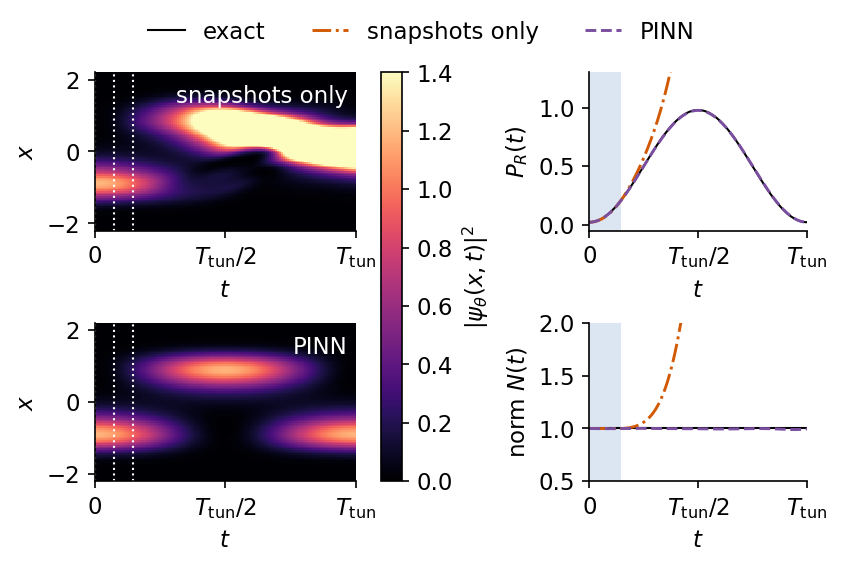

In [31]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 2, figsize=(5.5, 3.7), layout="constrained", gridspec_kw={"width_ratios": [1.2, 1]})
    for ax, key, title in ((axs[0, 0], "A", "snapshots only"), (axs[1, 0], "B", "PINN")):
        im = density_map_dw(ax, runs_dw[key]["dens"], snaps=T_SNAP_DW)
        ax.text(0.97, 0.92, title, color="w", ha="right", va="top", transform=ax.transAxes)
    fig.colorbar(im, ax=axs[:, 0], label=r"$|\psi_\theta(x,t)|^2$", pad=0.02)
    for ax, q, lab in ((axs[0, 1], "pr", "$P_R(t)$"), (axs[1, 1], "norm", "norm $N(t)$")):
        ax.axvspan(0, T_SNAP_DW.max(), color="#DCE6F2", lw=0, zorder=0)
        ax.plot(T_DW, PR_DW if q == "pr" else NORM_DW, color=COL["exact"], lw=1.0, label="exact")
        ax.plot(T_DW, runs_dw["A"][q], "-.", color=COL["data"], label="snapshots only")
        ax.plot(T_DW, runs_dw["B"][q], "--", color=COL["PINN"], label="PINN")
        ax.set_xlabel("$t$"); ax.set_ylabel(lab); tun_ticks(ax)
    axs[0, 1].set_ylim(-0.05, 1.3); axs[1, 1].set_ylim(0.5, 2.0)      # model A leaves both ranges
    fig.legend(*axs[0, 1].get_legend_handles_labels(), loc="outside upper center", ncol=3, handlelength=1.6)
    save(fig, "fig_lab045_dw_models"); plt.show()

<hr/>
## 9. Unknown barrier height

The splitting $\Delta E$, and with it the tunnelling period, depends exponentially on the barrier. We now treat the barrier height $V_0$ as unknown and estimate it from the three snapshots of the double well. Since the energy zero $\bar E$ depends on $V_0$, the constant $\varepsilon$ in the potential $V_0(x^2/a^2-1)^2-\varepsilon$ is unknown as well, and the PINN learns $\log V_0$ and $\varepsilon$ together with the network weights. The offset $\varepsilon$ is fixed by the global phase that the synthetic snapshots carry, a phase convention that density measurements would leave undetermined. It is optimised independently of $V_0$, so it may differ from the doublet mean energy at each trial barrier. It starts from $V_0=3$ and from the doublet mean $\varepsilon=\bar E(V_0=3)$ obtained by diagonalising the Hamiltonian with this barrier, and uses the loss and the budget of model B.

The classical reference is again least squares through the split-step solver. We propagate the interpolated first snapshot to $t=2$ with $\Delta t=0.01$ in the potential $V_0(x^2/a^2-1)^2-\varepsilon$, compare with the two later snapshots,
$$\chi^2(V_0,\varepsilon)=\sum_{k\,:\,t_k>0}\ \sum_j\big|\psi_{\rm SSF}(x_j,t_k;V_0,\varepsilon)-\psi_{jk}\big|^2,$$
and minimise over both parameters with the Nelder–Mead simplex method of `scipy.optimize.minimize` from the same starting point. Twenty further noise realisations give the spread of the least-squares estimate. Finally the splitting $\Delta E(V_0)$ is computed by diagonalisation for barrier heights between 2 and 6, which shows how strongly the tunnelling period constrains $V_0$.

In [32]:
from scipy.optimize import minimize
V0_INIT = 3.0
EPS_INIT = float(np.linalg.eigvalsh(fourier_hamiltonian(lambda x: v_dw(x, V0_INIT)))[:2].mean())

# PINN with trainable log V0 and energy zero eps, same snapshots, network and budget as model B
q0 = (init_mlp(jax.random.key(0), SIZES), jnp.log(jnp.asarray(V0_INIT, F32)), jnp.asarray(EPS_INIT, F32))
q_dw, h_dw = train(make_loss_dw(net_dw, learn=True), q0, monitor=lambda q: float(jnp.exp(q[1])))
v0_pinn, eps_pinn = float(jnp.exp(q_dw[1])), float(q_dw[2])
res_dw_inv = evaluate_dw(net_dw, q_dw[0], name="inverse PINN")
# the same error after removing at every time the global phase arg <psi|psi_theta>
ov = np.sum(np.conj(PSI_DW) * res_dw_inv["psi"], -1)
err_inv_phase = np.abs(res_dw_inv["psi"] * np.exp(-1j * np.angle(ov))[:, None] - PSI_DW).max(-1)
print(f"   after removing the global phase at every time: max |psi_theta - psi| = {err_inv_phase.max():.1e}, "
      f"phase at t = T_tun {np.angle(ov[-1]):.3f}")

# least squares through the split-step solver
N_LS = 200; DT_LS = T_SNAP_DW.max() / N_LS
IDX_LS = np.round(T_SNAP_DW / DT_LS).astype(int)
ssf_ls = jax.jit(lambda p0, V: split_step(p0, DT_LS, N_LS, V=V))
def ls_objective_dw(par, snaps):
    v0, eps = par
    p0 = np.interp(X, X[I_DATA], snaps[0].real) + 1j * np.interp(X, X[I_DATA], snaps[0].imag)
    psis = np.asarray(ssf_ls(jnp.asarray(p0), jnp.asarray(v_dw(X, v0) - eps)))
    return float(sum(np.sum(np.abs(psis[i][I_DATA] - snaps[k])**2) for k, i in enumerate(IDX_LS) if k > 0))
def ls_fit(snaps):
    return minimize(ls_objective_dw, x0=(V0_INIT, EPS_INIT), args=(snaps,), method="Nelder-Mead",
                    options=dict(xatol=1e-6, fatol=1e-12, maxiter=2000)).x
v0_ls, eps_ls = ls_fit(psi_snap_dw)
psi_clean_dw = psi_dw_exact(T_SNAP_DW)[:, I_DATA]
v0_ls_rep = []
for seed in range(101, 121):
    r_ = np.random.default_rng(seed)
    v0_ls_rep.append(ls_fit(psi_clean_dw + SIGMA * (r_.normal(size=psi_clean_dw.shape)
                                                    + 1j * r_.normal(size=psi_clean_dw.shape)))[0])
v0_ls_rep = np.array(v0_ls_rep)

# splitting against barrier height
V0_SCAN = np.linspace(2.0, 6.0, 41)
DE_SCAN = np.array([np.diff(np.linalg.eigvalsh(fourier_hamiltonian(lambda x: v_dw(x, v)))[:2])[0] for v in V0_SCAN])
dlog = np.gradient(np.log(DE_SCAN), V0_SCAN)[np.argmin(np.abs(V0_SCAN - V0_DW))]
de_of = lambda v: float(np.interp(v, V0_SCAN, DE_SCAN))
print(f"true V0 = {V0_DW:g}, eps = {E_BAR:.4f}; start V0 = {V0_INIT:g}, eps = {EPS_INIT:.4f}")
print(f"PINN: V0 = {v0_pinn:.4f}, eps = {eps_pinn:.4f} after {h_dw['time']:.0f} s")
print(f"least squares: V0 = {v0_ls:.4f}, eps = {eps_ls:.4f}; over 20 further noise realisations "
      f"mean {v0_ls_rep.mean():.4f}, std {v0_ls_rep.std(ddof=1):.4f}")
print(f"d ln(Delta E)/d V0 at V0 = {V0_DW:g}: {dlog:.3f}; Delta E from {DE_SCAN[0]:.3f} at V0 = 2 to {DE_SCAN[-1]:.4f} at V0 = 6")
print(f"tunnelling period implied by the PINN estimate {2 * np.pi / de_of(v0_pinn):.2f}, by least squares "
      f"{2 * np.pi / de_of(v0_ls):.2f}, true {T_TUN:.2f}")
nums["dw_inverse"] = dict(v0_init=V0_INIT, eps_init=EPS_INIT, v0_pinn=v0_pinn, eps_pinn=eps_pinn, v0_ls=float(v0_ls),
                          eps_ls=float(eps_ls), ls_mean=float(v0_ls_rep.mean()), ls_std=float(v0_ls_rep.std(ddof=1)),
                          time=h_dw["time"], err=float(res_dw_inv["err"].max()), dlog=float(dlog),
                          err_phase=float(err_inv_phase.max()), phase_end=float(np.angle(ov[-1])),
                          pr_err=res_dw_inv["s"]["pr_err"],
                          de_2=float(DE_SCAN[0]), de_6=float(DE_SCAN[-1]),
                          T_pinn=2 * np.pi / de_of(v0_pinn), T_ls=2 * np.pi / de_of(v0_ls))

inverse PINN: max |psi_theta - psi| for t <= 2: 6.1e-03, later: 6.7e-02; norm between 0.991 and 1.000
   max |P_R,theta - P_R| = 4.0e-02, largest P_R 0.977 at t = 6.90, fitted period 13.81 (T_tun = 13.59)
   after removing the global phase at every time: max |psi_theta - psi| = 6.8e-02, phase at t = T_tun -0.008


true V0 = 4, eps = 2.5209; start V0 = 3, eps = 2.1562
PINN: V0 = 4.0999, eps = 2.5546 after 176 s
least squares: V0 = 4.0943, eps = 2.5528; over 20 further noise realisations mean 3.9733, std 0.0786
d ln(Delta E)/d V0 at V0 = 4: -0.217; Delta E from 0.692 at V0 = 2 to 0.2971 at V0 = 6
tunnelling period implied by the PINN estimate 13.89, by least squares 13.87, true 13.59


During the Adam stage the PINN estimate of $V_0$ first drops and then settles slightly above 4. Under L-BFGS it moves to $V_0=4.100$, with $\varepsilon=2.555$ against the true $\bar E=2.521$. The least-squares fit gives $V_0=4.094$ and $\varepsilon=2.553$ on the same data, and over 20 further noise realisations its estimates have the mean 3.973 and the standard deviation 0.079. On the first data set both estimates lie within 1.3 standard deviations of the true value and agree with each other to 0.006. The training takes 176 s.

The splitting falls from 0.692 at $V_0=2$ to 0.297 at $V_0=6$, with the logarithmic derivative $d\ln\Delta E/dV_0=-0.217$ at $V_0=4$. The estimated barriers give the tunnelling periods 13.89 (PINN) and 13.87 (least squares) against the true 13.59, so an error of 2.5 % in $V_0$ becomes an error of 2.2 % in $T_{\rm tun}$. The probability $P_R$ of the inverse PINN deviates from the exact one by at most $4.0\times10^{-2}$ over the window, more than for model B, as expected from the shifted period. The fit of its $P_R(t)$ gives the period 13.81. Its wave function deviates from the exact one by up to $6.7\times10^{-2}$, and removing at every time the unobservable global phase $\arg\langle\psi|\psi_\theta\rangle$ leaves this error at $6.8\times10^{-2}$, so the deviation is consistent with the shifted period. The left panel of the figure shows the PINN estimate of $V_0$ against the iteration with the switch to L-BFGS dotted. The right panel shows $\Delta E(V_0)$ on a logarithmic axis together with the starting value and the two estimates.

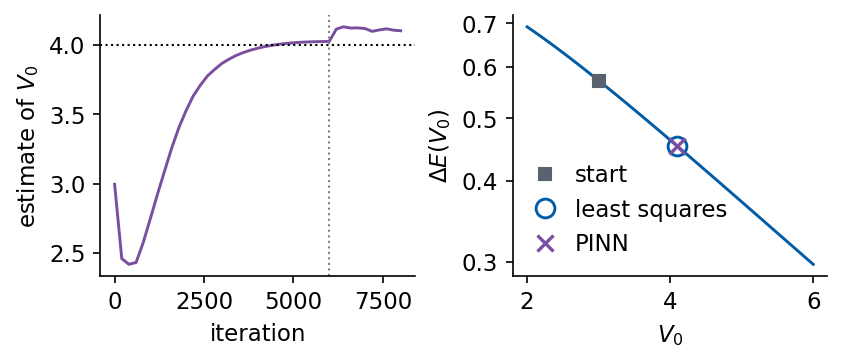

In [33]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.3), layout="constrained")
    ax = axs[0]
    ax.plot(h_dw["it"], h_dw["mon"], color=COL["PINN"])
    ax.axhline(V0_DW, color="k", ls=":", lw=1.0); ax.axvline(6000, color="0.5", ls=":", lw=1.0)
    ax.set_xlabel("iteration"); ax.set_ylabel(r"estimate of $V_0$")
    ax = axs[1]
    ax.semilogy(V0_SCAN, DE_SCAN, color=COL["SSF"])
    ax.plot([V0_INIT], [de_of(V0_INIT)], "s", color=UJGray, ms=6, label="start")
    ax.plot([v0_ls], [de_of(v0_ls)], "o", mfc="none", mec=COL["SSF"], ms=9, mew=1.4, label="least squares")
    ax.plot([v0_pinn], [de_of(v0_pinn)], "x", color=COL["PINN"], ms=8, mew=1.6, label="PINN")
    ax.set_xlabel("$V_0$"); ax.set_ylabel(r"$\Delta E(V_0)$")
    ax.set_yticks([0.3, 0.4, 0.5, 0.6, 0.7]); ax.set_yticklabels(["0.3", "0.4", "0.5", "0.6", "0.7"])
    ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
    ax.legend(loc="lower left", handlelength=1.0)
    save(fig, "fig_lab045_dw_inverse"); plt.show()

<hr/>
## 10. Physics in the residual

The residual contains the Hamiltonian, and through it the PINN inherits the structure of quantum dynamics to the degree that the residual is small. The exact evolution $e^{-i\hat Ht}$ is unitary because $\hat H$ is Hermitian, so the norm is conserved, and it commutes with $\hat H$, so the energy is conserved. Neither property is part of the loss. The PINN keeps the norm of the harmonic-trap state between 0.999 and 1.002 and its energy between 0.999 and 1.002, and the norm of the double-well state between 0.989 and 1.001, as expected for a function that nearly solves the equation. The snapshots-only networks violate both conservation laws as soon as they leave the data.

Conservation of the norm and of the energy is a necessary check and an insufficient one. The family of wave functions
$$\psi_\alpha(x,t)=\frac{\phi_0(x)e^{-iE_0t}+\phi_1(x)e^{-i\alpha t}}{\sqrt2}$$
with any real $\alpha$ has the norm 1 and the energy $\langle\hat H\rangle=(E_0+E_1)/2=1$, by the orthonormality of $\phi_0$ and $\phi_1$. Its density oscillates with the frequency $|\alpha-E_0|$, which in general differs from the true beat frequency $E_1-E_0=1$. Inserting $\psi_\alpha$ into the complex residual $R=i\partial_t\psi-\hat H\psi$ gives
$$R_\alpha=\frac{(\alpha-E_1)\,\phi_1(x)\,e^{-i\alpha t}}{\sqrt2},$$
which vanishes only for $\alpha=E_1$. Both conservation checks pass for the whole family, and only the residual, the phase and the error against the exact solution single out the correct evolution.

The spectrum enters through the time dependence. A function with vanishing residual is a superposition of stationary states with the phases $e^{-iE_nt}$, so the residual fixes the frequencies $E_n-E_m$ of every observable. In the trap these frequencies set the period $2\pi$ of $\langle x\rangle(t)$. In the double well they set the tunnelling period $2\pi/\Delta E$, which the PINN reproduced as 13.60 for 13.587 from snapshots covering 15 % of it. The inverse problems use the same property in reverse. A different $\omega$ or $V_0$ changes the frequencies, and the snapshots together with the residual select the parameter consistent with both.

The residual is linear and homogeneous in $\psi$, so $\psi=0$ solves it and satisfies the boundary term, and the amplitude of the solution is fixed only by the snapshots. The failed runs, without envelope in the trap and with the wide envelope or the unshifted energy zero in the double well, lose norm and drift towards this trivial solution. The global phase $e^{-i\bar Et}$ carries no physics, and shifting the energy zero improved the double-well fit in the tested runs. A classical solver needs none of these adaptations. The split-step method integrates both examples more accurately in a fraction of a second, and it remains the method of choice for the forward problem. The PINN combines noisy snapshots at arbitrary times with the equation in one fit and returns unknown parameters of the Hamiltonian from the same training.

<hr/>
## Summary

A particle in a harmonic trap prepared in $(\phi_0+\phi_1)/\sqrt2$ oscillates with the period $2\pi$, its density sloshes from one side of the trap to the other, its norm stays 1 and its mean position follows $\cos t/\sqrt2$. From three noisy snapshots of the wave function in the first sixth of the period, a neural network fitted to the snapshots alone reproduces the data and fails beyond them, with an error of 1.2 and a norm between 0.719 and 1.652. The same network trained with the residual of the Schrödinger equation on the whole period predicts the evolution after the last snapshot with a maximal error of $4.0\times10^{-3}$, keeps the norm between 0.999 and 1.002 and follows the mean position to $6.4\times10^{-3}$. The improvement comes from the equation of motion in the loss. Without the envelope $e^{-x^2/4}$ the PINN loses norm and its error reaches 0.36.

The comparison with classical methods sets the scope of these results. The split-step Fourier method solves the forward problem to $8.4\times10^{-6}$ in $7.5\times10^{-3}$ s, and with the known eigenstates the snapshots determine the evolution to $6.1\times10^{-3}$ by a projection. The PINN reaches a similar accuracy as the projection after 73 s of training. With an unknown trap frequency the PINN estimates $\omega=0.9952$, within the statistical spread of a least-squares fit through the split-step solver. These conclusions refer to the network, budget and single training run of each model in this notebook.

Varying the data shows where the information of the PINN comes from. A single snapshot at $t=0$ already gives a largest error of $2.2\times10^{-2}$ over the period, three snapshots lower it to $7.0\times10^{-3}$ at half the training budget, and more snapshots bring no further gain. The noise level $\sigma=0.05$ raises the error to $3.1\times10^{-2}$. The PINN conserves the energy to $2.3\times10^{-3}$ and reproduces the real and imaginary parts of $\psi$ far outside the observation window.

In the symmetric double well with $V_0=4$ the two lowest states form a doublet with the splitting $\Delta E=0.4624$, and a particle prepared in the left well tunnels to the right well and back within $T_{\rm tun}=13.587$, which a classical particle of the same energy cannot do. From three snapshots in the first 15 % of this period the PINN predicts the whole oscillation, with $P_R(t)$ accurate to $3.3\times10^{-3}$, the norm between 0.989 and 1.001 and the fitted period 13.60. This run used a narrow envelope and an energy zero at the mean energy of the doublet, and the two tested alternatives, a wider envelope or the unshifted energy zero, decayed towards $\psi=0$ at the same training budget. The PINN estimates the barrier height as $V_0=4.100$, in agreement with a least-squares fit through the split-step solver, $V_0=4.094$, whose statistical spread is 0.079.

## Exercises

1. Prepare a coherent state of the harmonic trap, the ground state displaced to $x_0=1.5$, and train the PINN of Section 3 on three early snapshots. Compare the predicted $\langle x\rangle(t)$ with the classical trajectory $x_0\cos t$ and check whether the width of the packet stays constant.
2. Replace the initial state by $(\phi_0+\phi_1+\phi_2)/\sqrt3$ and then the potential by the anharmonic trap $V(x)=\tfrac12x^2+\lambda x^4$. Compute the spectrum by diagonalisation, explain from the level spacings when the density returns to its initial form, and test how far in time the PINN follows the exact evolution.
3. Use snapshots of the density $|\psi|^2$ alone and replace the snapshot term by $\big(|\psi_\theta(x_j,t_k)|^2-n_{jk}\big)^2$. Find out which part of the phase of $\psi$ the residual restores and which part stays undetermined.
4. Tilt the double well, $V(x)\to V(x)+\delta\,x$. Derive the largest $P_R$ in the two-state approximation, compare it with the split-step evolution for a few values of $\delta$, and train the PINN on the tilted well.

## References

- M. Raissi, P. Perdikaris, G. E. Karniadakis, *Physics-informed neural networks: a deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations*, J. Comput. Phys. **378**, 686 (2019), [doi:10.1016/j.jcp.2018.10.045](https://doi.org/10.1016/j.jcp.2018.10.045)
- D. J. Griffiths, D. F. Schroeter, *Introduction to Quantum Mechanics*, 3rd ed., Cambridge University Press (2018), [doi:10.1017/9781316995433](https://doi.org/10.1017/9781316995433)
- J. A. Fleck, J. R. Morris, M. D. Feit, *Time-dependent propagation of high energy laser beams through the atmosphere*, Appl. Phys. **10**, 129 (1976), [doi:10.1007/BF00896333](https://doi.org/10.1007/BF00896333)
- G. Strang, *On the construction and comparison of difference schemes*, SIAM J. Numer. Anal. **5**, 506 (1968), [doi:10.1137/0705041](https://doi.org/10.1137/0705041)
- L. D. Landau, E. M. Lifshitz, *Quantum Mechanics: Non-Relativistic Theory*, 3rd ed., Pergamon (1977), [doi:10.1016/C2013-0-02793-4](https://doi.org/10.1016/C2013-0-02793-4)
- D. P. Kingma, J. Ba, *Adam: a method for stochastic optimization*, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)
- D. C. Liu, J. Nocedal, *On the limited memory BFGS method for large scale optimization*, Math. Program. **45**, 503 (1989), [doi:10.1007/BF01589116](https://doi.org/10.1007/BF01589116)